# **1. Problem Framing and Hypotheses**

## **1.1 O Contexto do Problema**

### **As decisões**

Perante a Sofia estão diversas decisões, a vários níveis:

- **Definição de objetivos:** existem três opções principais: prever que colaboradores têm intenção de sair; descobrir que fatores são mais preponderantes no nível de exaustão; ou segmentar os colaboradores em perfis.
- **Nível metodológico:** serão tomadas decisões relativas ao tratamento dos dados, tais como o preenchimento de *missing values*, a substituição de valores evidentemente errados (ex.: idade = 2) ou o tratamento dado a informações de foro pessoal, como idade, género ou a existência de filhos.
- **Estratégia de intervenção:** terá de ser elaborada uma estratégia ao nível das aplicações internas para colaboradores que, procurando satisfazer as necessidades dos mesmos e reduzir o *turnover*, não comprometa questões éticas nem recorra a *dark patterns*.

### **Os stakeholders**

A estratégia a adotar depende das necessidades e objetivos de diferentes stakeholders:

- **Os 3 diretores de RH**, que pretendem principalmente reduzir os custos associados ao *turnover*. Apesar de partilharem este objetivo, bem como um alinhamento comum com as práticas da Indústria 5.0, podem ter interesses competitivos distintos, e existe uma preocupação manifesta com o respeito por princípios éticos nas estratégias de retenção.
- **Os colaboradores**, que, para além de beneficiarem de uma alocação mais eficiente de recursos em programas de retenção, podem estar expostos a riscos através dos dados pessoais disponibilizados, ou devido a eventuais medidas de intervenção mais predatórias (*dark patterns*).

### **O mesmo conjunto de dados, 3 empresas**

A criação de um dataset comum apresenta benefícios, mas também limitações. Permite, por um lado, aplicar de forma mais eficaz métodos que necessitam de grandes volumes de dados, como o *machine learning*. Por outro lado, as conclusões obtidas serão mais generalistas para o mercado em estudo e não necessariamente aplicáveis a necessidades concretas de uma empresa em particular, uma vez que não existe identificador de empresa.

---

## **1.2 Framing & Hypotheses**

### **A questão central**

No problema em estudo, o principal objetivo será prever, a partir dos dados do questionário, quais os colaboradores que declaram maior intenção de procurar um novo emprego e quais são os principais fatores que motivam este risco. Para isso, será selecionada uma variável target, e, será construído um modelo de classificação supervisionada, cuja generalização será avaliada em dados reservados para teste. O número limitado de observações (560 antes da limpeza) recomenda prudência na interpretação das métricas.

### **Target**
Ao definir qual deve ser a variável *target* a prever pelo modelo, há que considerar que as opções disponíveis (*exhaustion*, *intention to look for a new job* e *intention to quit*) podem representar etapas distintas na experiência do colaborador. Uma sequência conceptual possível é exaustão → procura de oportunidades → intenção de saída. Contudo, os dados são transversais e não demonstram que esta sequência temporal ou causal aconteça necessariamente.

Atuar em pontos diferentes deste *pipeline* poderá produzir efeitos distintos. Por exemplo, se um colaborador exausto for identificado, poderá ser "recaptado" antes de manifestar intenções mais "sérias" de saída. Por outro lado, a exaustão pode ser um indicador pouco robusto, uma vez que não responde diretamente ao problema "quem pretende sair".

### **Comparação dos possíveis targets**

| Target | Vantagens | Desvantagens |
|---|---|---|
| **`intention_quit`** | Mais próximo do comportamento real de saída e da pergunta dos diretores ("quem vamos perder?"). Fácil de comunicar e de transformar numa lista acionável. | Média de 3,33 na escala 1–7; uma definição binária exigiria justificar o limiar e avaliar a distribuição resultante. Sinal mais tardio: quem já decidiu sair é mais difícil de reter. |
| **`intention_lookfornewjob`** | Sinal mais precoce, portanto mais acionável (ainda há margem para intervir). Média de 2,64 (e não 2,90); é necessário analisar os vários limiares para avaliar a distribuição das classes. | Procurar emprego não implica sair (pode ser curiosidade ou negociação). Proxy mais ruidoso do *turnover* real. Provavelmente muito correlacionada com `intention_quit`. |
| **`Exhaustion`** | Distribuição mais equilibrada e mais "contínua". Muito acionável (carga de trabalho, bem-estar). Sinal ainda mais precoce no *pipeline*. | Não responde diretamente à pergunta do caso: é um estado e não uma decisão. Teoricamente é mais um *driver* (ou mediador) do que o resultado final. Escala diferente das restantes (1-5, com 5 = pior). |

**Escolha e papel das restantes variáveis:** o *target* principal será `intention_lookfornewjob`, por constituir uma variável de compromisso: suficientemente próxima da decisão de saída, mas num ponto do *pipeline* em que ainda é possível intervir. A `intention_quit` será excluída das *features* (para evitar *data leakage*, por ser quase uma reformulação do *target*). A `Exhaustion` será mantida como variável (burnout → intenção de procurar emprego).

### **Tratamento do target como variável binária**

Para efeitos operacionais ("quem está em risco?"), o *target* será transformado numa variável binária, em que valores abaixo de um determinado limiar correspondem a "sem risco" (0) e valores iguais ou acima a "em risco" (1). Esta opção facilita a comunicação e a ação por parte dos diretores, bem como a utilização de métricas próprias de modelos de classificação (*recall*, *precision*, F1, ROC-AUC).

No entanto, esta simplificação implica perder alguma **sensibilidade** da escala ordinal original (1-7): colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes, e a escolha do limiar é, por natureza, algo arbitrária. Para justificar a decisão, vamos comparar a percentagem de colaboradores assinalados com três limiares possíveis (≥ 3, ≥ 4 e ≥ 5). Manteremos sempre a resposta original de 1 a 7.

### **Hipóteses a Testar**

| ID | Hipótese | Variáveis a testar | Relação esperada |
|---|---|---|---|
| H1 | **Clima organizacional:** Uma perceção mais positiva do clima organizacional (confiança, comunicação, justiça e camaradagem) está associada a uma menor intenção de procurar um novo emprego. | `ca_camaraderie`, `ca_leadersCredibility`, `ca_leaderCommunication`, `ca_Personal_Development`, `ca_justice`, `ca_work_family` | Negativa |
| H2 | **Características do trabalho:** Características profissionais mais favoráveis (variedade de competências, identidade e significado das tarefas, autonomia e feedback) estão associadas a uma menor intenção de procurar um novo emprego. | `Skill_Variety`, `Task_Identity`, `Task Significance`, `Autonomy`, `Feedback` | Negativa |
| H3 | **Exaustão:** Níveis mais elevados de exaustão dos colaboradores estão associados a uma maior intenção de procurar um novo emprego. | `Exhaustion` | Positiva |
| H4 | **Desenvolvimento profissional:** Uma menor perceção de oportunidades de desenvolvimento pessoal e progressão na carreira está associada a uma maior intenção de procurar um novo emprego. | `ca_Personal_Development`, `n_progressions`, `years_in_position` | Negativa* |
| H5 | **Antiguidade:** A antiguidade na empresa e na função está associada à intenção de procurar um novo emprego, podendo existir uma relação não linear. | `years_in_company`, `years_in_position` | Não linear** |
| H6 | **Formação e progressão:** Colaboradores com mais formação e progressões na carreira tendem a apresentar uma menor intenção de procurar um novo emprego. | `training` (3 variáveis), `n_progressions` | Negativa |
| H7 | **Fatores sociodemográficos:** A intenção de procurar um novo emprego apresenta diferenças entre grupos sociodemográficos, nomeadamente em função da idade e do género. | `age`, `is_female` | Exploratória*** |

**Notas sobre as relações esperadas:**

- *H4: Espera-se uma relação negativa entre a perceção de oportunidades de desenvolvimento e a intenção de procurar emprego.
- **H5: Não se assume uma relação linear. Uma maior antiguidade poderá estar associada a uma menor intenção de saída, devido à integração e estabilidade profissional. Contudo, poderá também existir um aumento da intenção de saída em situações de estagnação profissional.
- ***H7: Não se define antecipadamente uma direção para a relação. Diferenças entre grupos etários ou de género serão investigadas empiricamente, sem assumir que determinado grupo apresenta necessariamente maior intenção de saída.

# **2. Data quality and cleaning**

O enunciado exige quantificar os dados em falta e os valores implausíveis, executar uma estratégia e justificar as perdas de informação. Mantemos em separado (i) as regras determinísticas de correção e (ii) a imputação estatística, que será ajustada apenas no treino durante o ponto 4.


In [ ]:
from pathlib import Path
import warnings
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", font_scale=0.93)
pd.set_option("display.max_columns", 60)
plt.rcParams["figure.dpi"] = 115

ficheiro = Path("people_operations_dataset.xlsx")
if not ficheiro.exists():
    candidato = Path("reference_data/people_operations_dataset.xlsx")
    if candidato.exists():
        ficheiro = candidato
    else:
        try:
            from google.colab import files
        except ImportError as erro:
            raise FileNotFoundError(
                "Coloca people_operations_dataset.xlsx na pasta do notebook."
            ) from erro
        print("Seleciona o ficheiro people_operations_dataset.xlsx:")
        carregados = files.upload()
        if "people_operations_dataset.xlsx" not in carregados:
            raise FileNotFoundError("O Excel esperado não foi carregado.")

df = pd.read_excel(ficheiro, sheet_name="dataframe")
print("Dataset original:", df.shape)
print("Nomes de colunas:")
display(pd.DataFrame({"variavel": df.columns, "tipo": df.dtypes.astype(str).values}))
display(df.head(5))

assert df.shape == (560, 28), "Verifica se carregaste o Excel correto."


Dataset original: (560, 28)
Nomes de colunas:


,variavel,tipo
0,indice,int64
1,age,float64
2,is_office,int64
3,is_female,int64
4,has_children,int64
5,marital status,float64
6,n_children,float64
7,position_in_Company,float64
8,years_in_position,float64
9,years_in_company,float64


,indice,age,is_office,is_female,has_children,marital status,n_children,position_in_Company,years_in_position,years_in_company,n_training_lastyear,n_training_job,n_training_personalDevelopment,n_progressions,Skill_Variety,Task_Identity,Task Significance,Autonomy,Feedback,ca_camaraderie,ca_leadersCredibility,ca_leaderCommunication,ca_Personal_Development,ca_justice,ca_work_family,Exhaustion,intention_lookfornewjob,intention_quit
0,0,51.0,1,0,1,4.0,1.0,5.0,4.0,24.0,3.0,1.0,1.0,6.0,7.0,5.0,6.0,7.0,5.0,4.5,4.0,4.0,4.0,4.0,4.0,2.5,1,1
1,1,50.0,1,1,0,0.0,0.0,4.0,25.0,25.0,3.0,3.0,3.0,0.0,NaN,5.0,6.0,6.0,5.0,4.0,4.0,4.0,4.0,4.0,4.0,2.0,2,3
2,2,23.0,1,1,0,0.0,0.0,4.0,0.3,0.3,5.0,5.0,4.0,0.0,1.0,5.0,5.0,3.0,NaN,4.0,4.0,NaN,3.5,5.0,4.0,2.0,7,1
3,3,37.0,1,0,1,3.0,2.0,4.0,1.0,0.8,1.0,1.0,1.0,1.0,7.0,7.0,5.0,6.0,6.0,3.5,4.0,3.0,4.0,3.0,3.0,2.5,1,2
4,4,34.0,1,1,1,4.0,3.0,3.0,4.0,0.3,0.0,0.0,0.0,0.0,5.0,7.0,7.0,5.0,4.0,2.5,3.0,NaN,2.0,3.0,3.0,4.5,5,6


## 2.1 Identificação dos valores em falta

Primeiro, contamos quantas respostas faltam em cada variável e em cada colaborador. Só depois decidimos entre eliminar linhas incompletas ou preencher os campos em falta.

Linhas com ≥ 1 valor em falta: 449/560 (80.2%)
Total de células em falta: 841
Percentagem global em falta: 5.36 %


,n_missing,pct_missing
variavel,,
ca_leaderCommunication,67,11.96
ca_Personal_Development,61,10.89
ca_work_family,59,10.54
Skill_Variety,54,9.64
ca_camaraderie,53,9.46
ca_leadersCredibility,53,9.46
n_training_job,49,8.75
Task Significance,44,7.86
n_training_lastyear,42,7.50


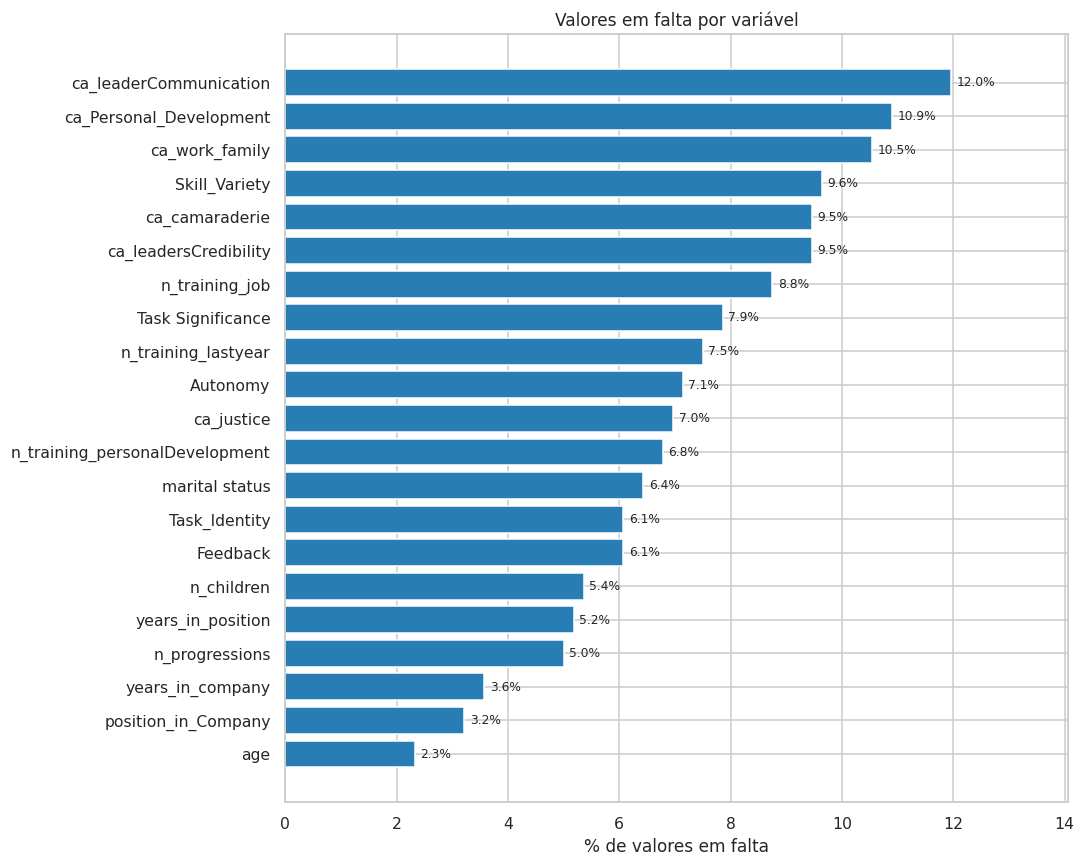

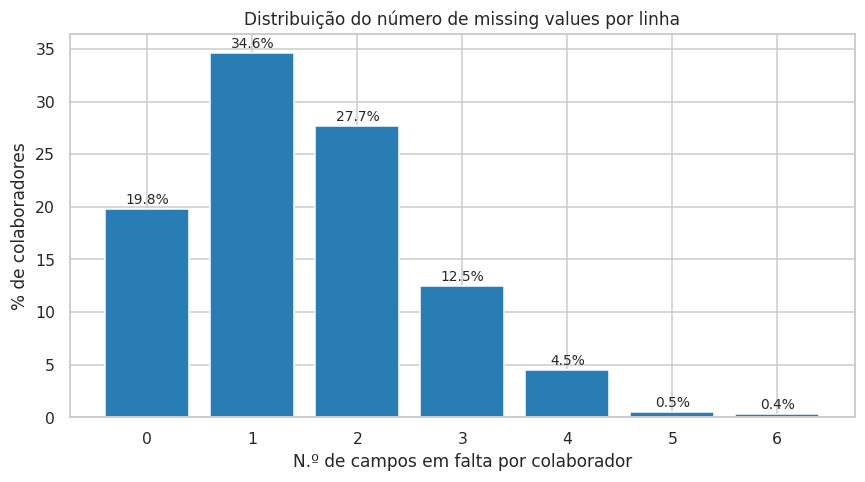

In [ ]:
# Diagnóstico dos valores em falta — tabela e dois gráficos
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": df.isna().mean() * 100,
}).sort_values("pct_missing", ascending=False)

rows_with_na = int(df.isna().any(axis=1).sum())
na_per_row = df.isna().sum(axis=1).value_counts().sort_index()

print(f"Linhas com ≥ 1 valor em falta: {rows_with_na}/{len(df)} "
      f"({rows_with_na / len(df) * 100:.1f}%)")
print("Total de células em falta:", int(df.isna().sum().sum()))
print("Percentagem global em falta:", round(df.isna().mean().mean() * 100, 2), "%")
display(missing.round(2).rename_axis("variavel"))

fig, ax = plt.subplots(figsize=(10, 8))
plot_missing = missing.loc[missing.pct_missing.gt(0)].sort_values("pct_missing")
ax.barh(plot_missing.index, plot_missing["pct_missing"], color="#287db5")
for i, valor in enumerate(plot_missing["pct_missing"]):
    ax.text(valor + 0.1, i, f"{valor:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, plot_missing.pct_missing.max() + 2.1)
ax.set_xlabel("% de valores em falta")
ax.set_title("Valores em falta por variável")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 4.5))
pct_rows = na_per_row / len(df) * 100
bars = ax.bar(na_per_row.index.astype(str), pct_rows.values, color="#287db5")
for bar, valor in zip(bars, pct_rows.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f"{valor:.1f}%", ha="center", fontsize=9)
ax.set_xlabel("N.º de campos em falta por colaborador")
ax.set_ylabel("% de colaboradores")
ax.set_title("Distribuição do número de missing values por linha")
plt.tight_layout()
plt.show()


### Resultados e estratégia de imputação

O primeiro passo na preparação de dados corresponde à identificação dos *missing values* no dataset. Para isso, elaborou-se o gráfico de barras que mostra, por ordem decrescente, as variáveis com maior percentagem de *missing values*.

Através do mesmo, conclui-se que as variáveis com maior percentagem de *missing values* são "Leader Communication", "Personal Development" e "Work Family", com mais de 10% dos valores em falta.

É interessante notar também que cerca de 75% das linhas têm entre 1 e 3 colunas sem valores, e que cerca de 20% do total não tem qualquer *missing value*. Assim, a estratégia mais adequada para tratar os *missing values* não será a eliminação (uma vez que isso implicaria eliminar 80% das linhas), mas sim a imputação.

### **Estratégia de imputação**

Dado que nenhuma variável tem mais de 12% de valores em falta, é aceitável recorrer a uma imputação simples, através de medidas de tendência central. Uma vez que a grande maioria das variáveis foi medida em escalas discretas ou corresponde a contagens com distribuição assimétrica, a média seria pouco adequada: nas escalas, pode produzir valores que não existem na escala de resposta e, nas contagens, é influenciada por poucos casos extremos. Recorrer-se-á, por isso, à **mediana**, que é também mais robusta a valores atípicos.

Exceção feita às variáveis "Estado Civil" (`marital status`) e "Posição na Empresa" (`position_in_Company`) que, por estarem associadas a códigos categóricos, serão imputadas com recurso à **moda**.

### **Perda de informação**

A imputação pela mediana (ou moda) atribui o mesmo valor a todos os casos em falta de uma variável, o que implica perda de informação. Por um lado, concentra os valores no centro da distribuição, reduzindo a variabilidade e enfraquecendo ligeiramente as correlações entre variáveis e com o *target*, o que pode levar a subestimar algumas associações testadas nas hipóteses. Por outro, ignora a relação com as restantes respostas do colaborador (por exemplo, o seu valor nos outros itens de clima) e não permite corrigir eventuais padrões de ausência de resposta não aleatória: se os colaboradores que não respondem forem sistematicamente diferentes (por exemplo, mais desligados da empresa), a imputação não recupera esse sinal e pode introduzir enviesamento. No caso da moda, a categoria mais frequente é ainda reforçada.

Estes efeitos são atenuados pela baixa proporção de valores em falta (cerca de 5% das células e no máximo 12% por variável). Na fase de modelação, a imputação será ajustada apenas nos dados de treino, para evitar fuga de informação para o teste.

### Porque escolhemos a mediana?

Os gráficos permitem comparar a **média (linha vermelha)** e a **mediana (linha verde)**. Por exemplo, em contagens de formação ou progressões há muitos valores pequenos e poucos muito altos. Esses valores extremos podem puxar a média para cima; a mediana representa melhor uma resposta típica. Nas variáveis categóricas, como o estado civil, usamos a **moda**, ou seja, a categoria mais frequente.

,Em falta,Média,Mediana,Mínimo,Máximo
age,13,38.35,37.0,2.0,73.0
n_children,30,1.00,1.0,0.0,5.0
years_in_position,29,6.24,4.0,0.0,35.0
years_in_company,20,9.75,10.0,0.1,43.0
n_training_lastyear,42,2.24,2.0,0.0,20.0
n_training_job,49,1.76,1.0,0.0,44.0
n_training_personalDevelopment,38,1.62,1.0,0.0,21.0
n_progressions,28,1.01,0.0,0.0,30.0
Skill_Variety,54,4.66,5.0,1.0,7.0
Task_Identity,34,4.72,5.0,1.0,7.0


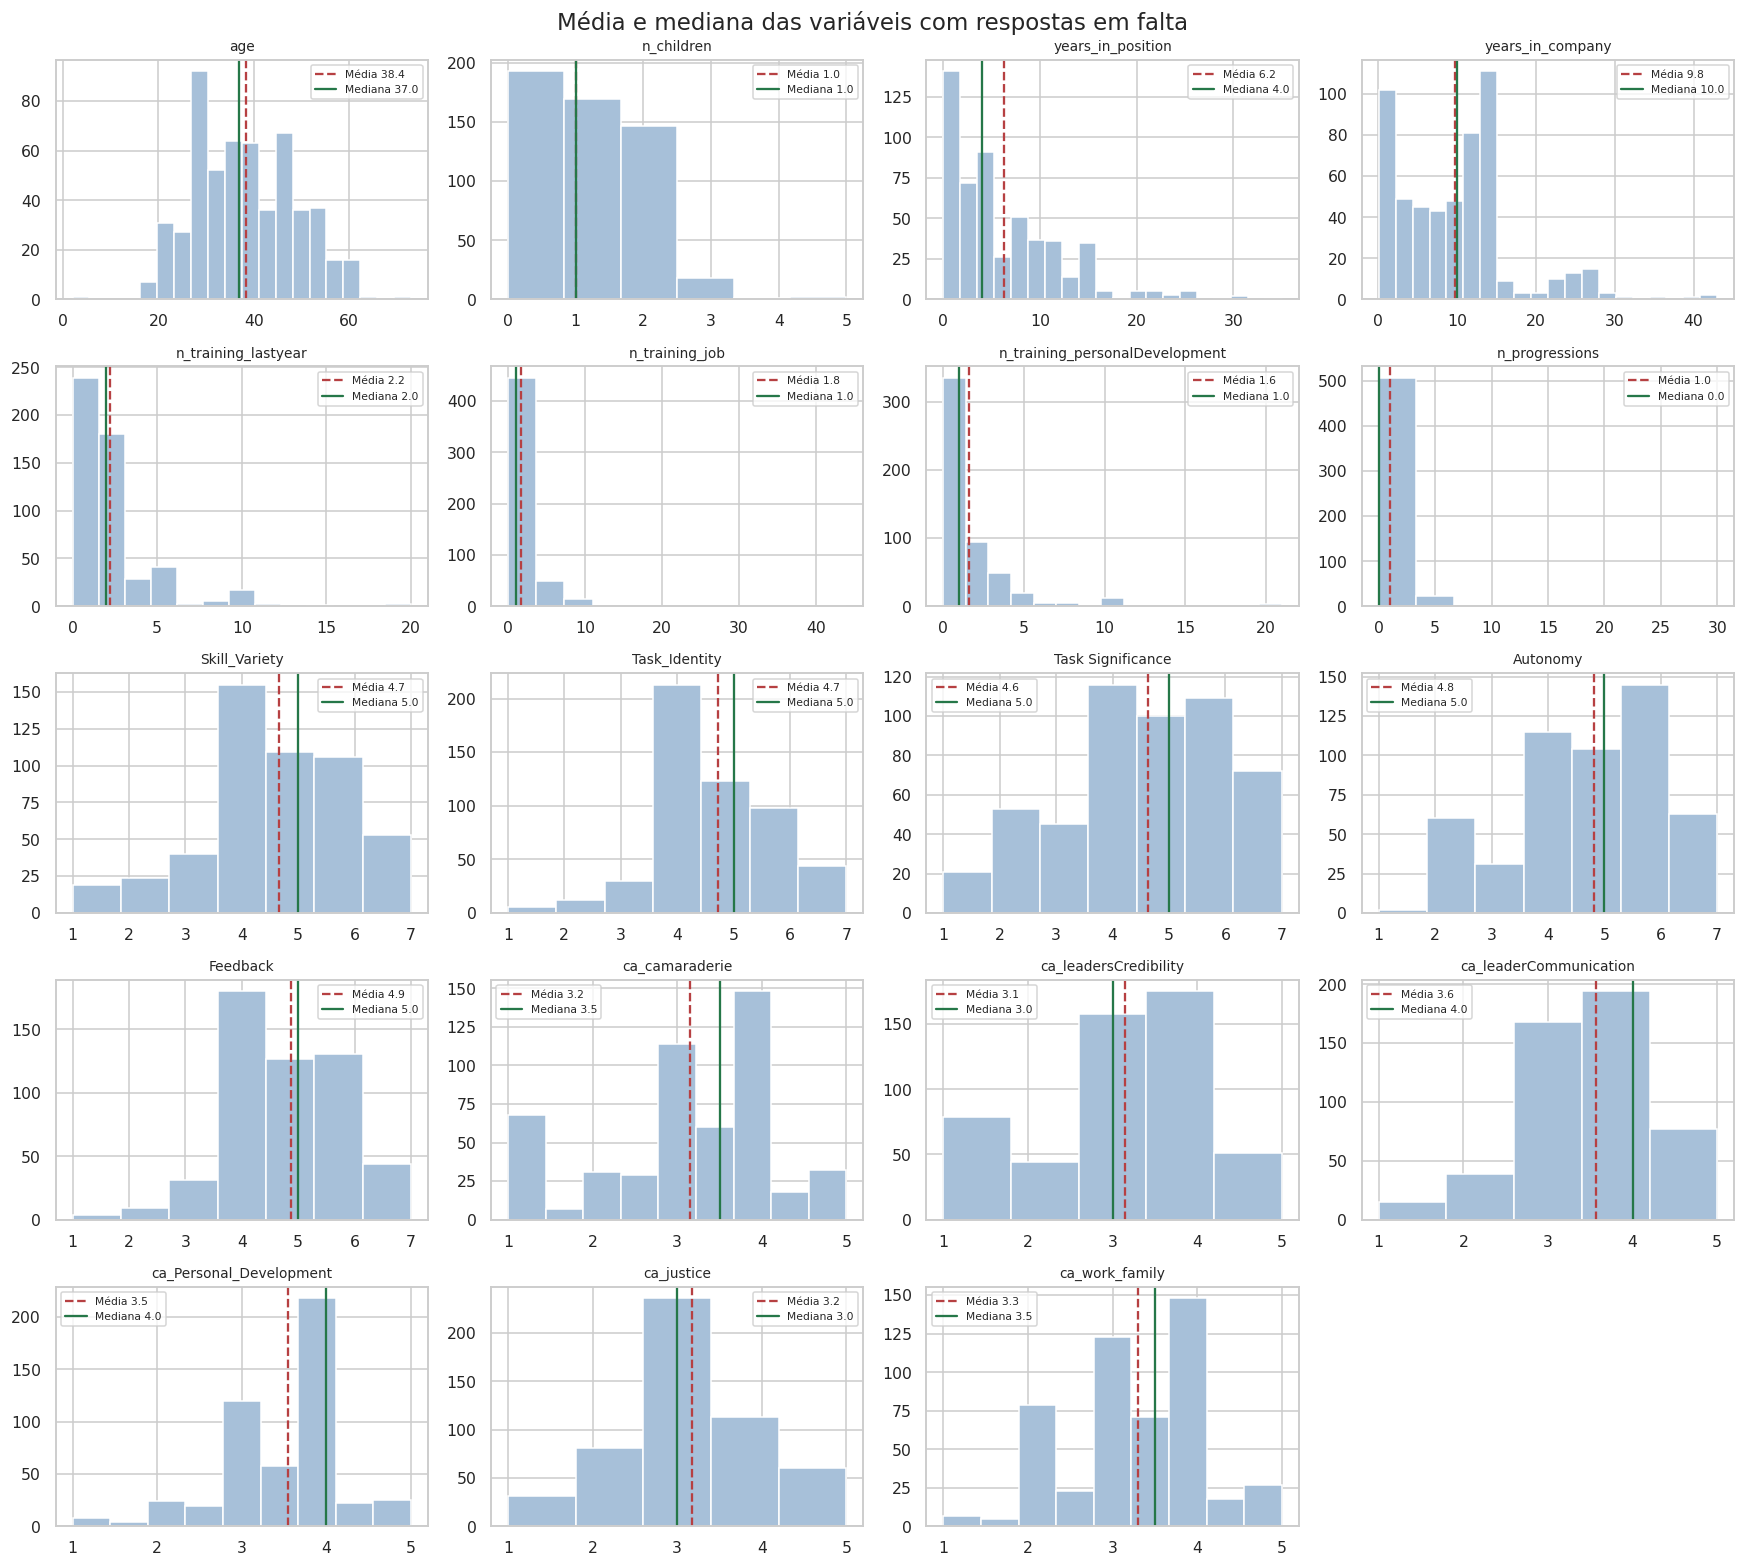

In [ ]:
# A média e a mediana não são iguais: observar as distribuições ajuda
# a escolher como preencher as respostas numéricas em falta.
categoricas = ["marital status", "position_in_Company"]
cols_com_faltas = [
    c for c in df.columns
    if df[c].isna().any() and c not in categoricas
]
resumo_central = pd.DataFrame({
    "Em falta": df[cols_com_faltas].isna().sum(),
    "Média": df[cols_com_faltas].mean(),
    "Mediana": df[cols_com_faltas].median(),
    "Mínimo": df[cols_com_faltas].min(),
    "Máximo": df[cols_com_faltas].max(),
})
display(resumo_central.round(2))

# As linhas verticais indicam a média (vermelho) e a mediana (verde).
n_colunas = 4
n_linhas = math.ceil(len(cols_com_faltas) / n_colunas)
fig, eixos = plt.subplots(n_linhas, n_colunas, figsize=(16, 2.9 * n_linhas))
eixos = np.asarray(eixos).flatten()
for eixo, coluna in zip(eixos, cols_com_faltas):
    valores = df[coluna].dropna()
    eixo.hist(valores, bins=min(20, valores.nunique()),
              color="#a7c0d9", edgecolor="white")
    eixo.axvline(valores.mean(), color="#b64042", ls="--",
                 label=f"Média {valores.mean():.1f}")
    eixo.axvline(valores.median(), color="#257748",
                 label=f"Mediana {valores.median():.1f}")
    eixo.set_title(coluna, fontsize=9)
    eixo.legend(fontsize=7)
for eixo in eixos[len(cols_com_faltas):]:
    eixo.axis("off")
fig.suptitle("Média e mediana das variáveis com respostas em falta", fontsize=15)
plt.tight_layout()
plt.show()

## 2.2 Identificação de valores implausíveis

Nem todo o valor diferente é um erro. Um colaborador com 73 anos, por exemplo, é um caso raro, mas possível. Já uma idade de 2 anos acompanhada de códigos inválidos em perguntas binárias é um problema de qualidade. Os gráficos seguintes ajudam a distinguir estes casos.

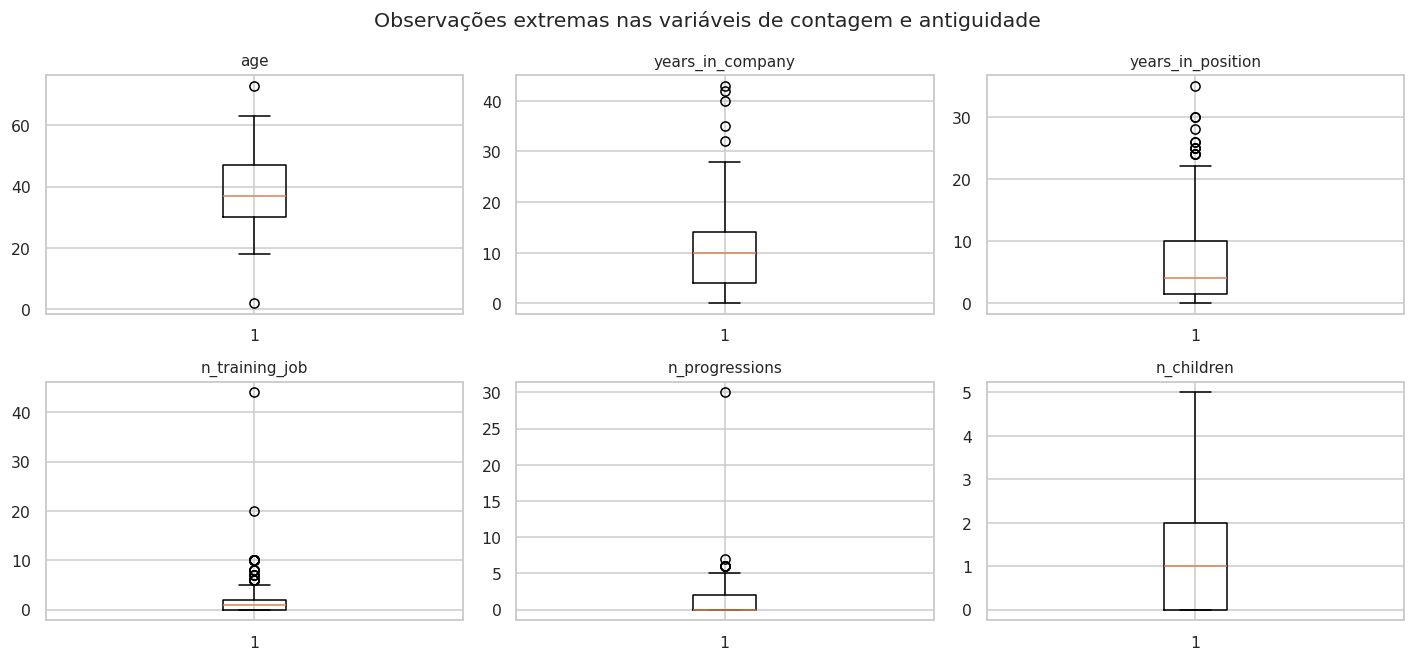

,Situação,Colaboradores
0,Anos na função > anos na empresa,15
1,Idade < 16 e dois códigos binários inválidos,1
2,Progressões > 20,1
3,Formações na função > 40,1
4,"Sem filhos, mas número de filhos em falta",13


,indice,age,is_female,is_office,years_in_company
16,5,2.0,5,3,0.4


In [ ]:
colunas_boxplot = [
    "age", "years_in_company", "years_in_position",
    "n_training_job", "n_progressions", "n_children"
]
fig, eixos = plt.subplots(2, 3, figsize=(13, 6.1))
for eixo, coluna in zip(eixos.flatten(), colunas_boxplot):
    eixo.boxplot(df[coluna].dropna())
    eixo.set_title(coluna, fontsize=10)
fig.suptitle("Observações extremas nas variáveis de contagem e antiguidade")
plt.tight_layout()
plt.show()

diagnostico = pd.DataFrame({
    "Situação": [
        "Anos na função > anos na empresa",
        "Idade < 16 e dois códigos binários inválidos",
        "Progressões > 20",
        "Formações na função > 40",
        "Sem filhos, mas número de filhos em falta",
    ],
    "Colaboradores": [
        int((df["years_in_position"] > df["years_in_company"]).sum()),
        int((df["age"].lt(16) &
             ~df["is_office"].isin([0, 1]) &
             ~df["is_female"].isin([0, 1])).sum()),
        int(df["n_progressions"].gt(20).sum()),
        int(df["n_training_job"].gt(40).sum()),
        int((df["has_children"].eq(0) & df["n_children"].isna()).sum()),
    ],
})
display(diagnostico)
display(df.loc[
    df["age"].lt(16) &
    ~df["is_office"].isin([0, 1]) &
    ~df["is_female"].isin([0, 1]),
    ["indice", "age", "is_female", "is_office", "years_in_company"],
])

## 2.3 Aplicação das correções

### O que corrigimos e porquê?

1. **Registo claramente corrompido:** existe uma resposta com idade igual a 2 anos e valores inválidos em duas variáveis que só deveriam conter 0 ou 1. Como não é possível reconstruir com segurança os valores certos, removemos apenas esta linha.
2. **Antiguidade incompatível:** foram encontrados 15 casos em que os anos na função ultrapassavam os anos na empresa. Corrigimos o tempo na função para o valor máximo plausível: os anos na empresa. Não alterámos a antiguidade na empresa.
3. **Valores extremos de formação e progressões:** os casos de 44 formações na função e 30 progressões destacam-se muito das restantes respostas. Como não temos confirmação dos valores verdadeiros, consideramos apenas esses campos como desconhecidos, sem eliminar o colaborador. Trata-se de uma decisão prudente, mas não podemos provar que sejam erros de introdução.
4. **Número de filhos:** quando `has_children = 0`, preencher `n_children = 0` é uma consequência lógica. Nos restantes casos, aplica-se a mediana.
5. **Valores raros mas possíveis:** mantemos, por exemplo, a idade de 73 anos. O facto de um ponto aparecer isolado num boxplot não significa, por si só, que esteja errado.

**Limitação:** a correção da antiguidade e a imputação são decisões metodológicas que podem influenciar resultados. Por isso, guardamos uma versão com as correções lógicas e outra com os valores em falta preenchidos para a exploração.

In [ ]:
# Limpeza determinística, reutilizável no ponto 4
def aplicar_regras_sem_imputar(dados):
    dados = dados.copy()

    #  detetar a linha corrompida por critérios e não por posição fixa
    mask_corrompida = (
        dados["age"].lt(16) &
        (~dados["is_office"].isin([0, 1])) &
        (~dados["is_female"].isin([0, 1]))
    )
    print("Linhas claramente corrompidas:", dados.index[mask_corrompida].tolist())
    dados = dados.loc[~mask_corrompida].copy()

    mask_anos = dados["years_in_position"] > dados["years_in_company"]
    dados.loc[mask_anos, "years_in_position"] = dados.loc[mask_anos, "years_in_company"]

    dados.loc[dados["n_progressions"] > 20, "n_progressions"] = np.nan
    dados.loc[dados["n_training_job"] > 40, "n_training_job"] = np.nan

    mask_filhos = dados["has_children"].eq(0) & dados["n_children"].isna()
    dados.loc[mask_filhos, "n_children"] = 0
    return dados


df_sem_imputacao = aplicar_regras_sem_imputar(df)
assert len(df_sem_imputacao) == 559
assert not (df_sem_imputacao["years_in_position"] >
            df_sem_imputacao["years_in_company"]).any()

#  imputação GLOBAL usada apenas nos testes exploratórios
df_clean = df_sem_imputacao.copy()
med_emp = df_clean["years_in_company"].median()
med_pos = df_clean["years_in_position"].median()
df_clean["years_in_company"] = df_clean["years_in_company"].fillna(
    np.maximum(med_emp, df_clean["years_in_position"].fillna(0)))
df_clean["years_in_position"] = df_clean["years_in_position"].fillna(
    np.minimum(med_pos, df_clean["years_in_company"]))

cat_cols = ["marital status", "position_in_Company"]
num_cols = [c for c in df_clean if df_clean[c].isna().any() and c not in cat_cols]
for col in num_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())
for col in cat_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

verificacao = pd.DataFrame({
    "Verificação": ["Linhas mantidas", "Missing finais",
                    "Violações de antiguidade", "Duplicados de índice"],
    "Valor": [len(df_clean), int(df_clean.isna().sum().sum()),
              int((df_clean["years_in_position"] >
                   df_clean["years_in_company"]).sum()),
              int(df_clean["indice"].duplicated().sum())]
})
display(verificacao)
assert df_clean.isna().sum().sum() == 0


Linhas claramente corrompidas: [16]


,Verificação,Valor
0,Linhas mantidas,559
1,Missing finais,0
2,Violações de antiguidade,0
3,Duplicados de índice,0


**Balanço do ponto 2:** partimos de 560 colaboradores e mantivemos 559. A versão exploratória está completa após imputação, enquanto a versão reservada para modelação mantém os valores desconhecidos para que sejam preenchidos apenas com informação do treino. Agora podemos investigar as relações entre as respostas.

# **3. Exploratory Data Analysis and Hypothesis Testing**

A análise exploratória procura determinar quais as hipóteses iniciais que encontram suporte nos dados e descobrir relações inesperadas. As medidas são associativas e não demonstram relações de causa e efeito. Para esta fase utiliza-se o `df_clean`, preservando-se em separado o `df_sem_imputacao` para o modelo supervisionado.


,count,mean,median,min,max
intention_lookfornewjob,559.0,2.637,2.0,1.0,7.0
intention_quit,559.0,3.326,4.0,1.0,7.0
Exhaustion,559.0,2.895,3.0,1.0,5.0


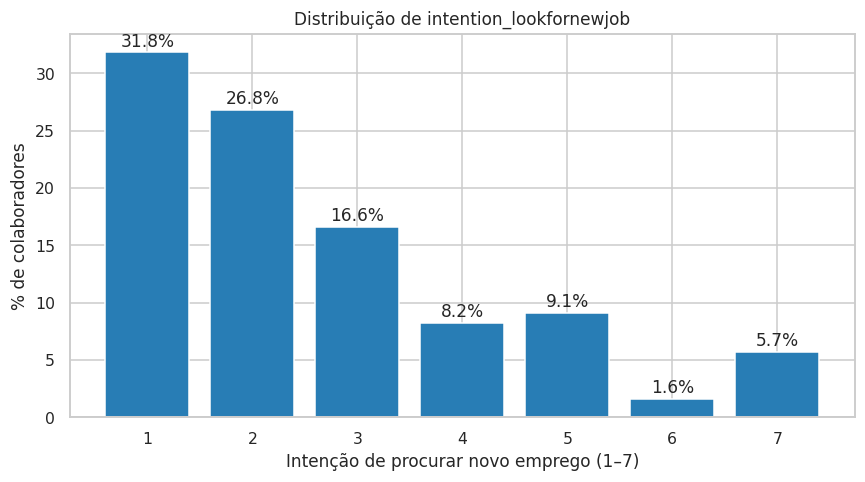

,pct_intention_quit_ge_5
intention_lookfornewjob,
1,9.0
2,8.7
3,30.1
4,34.8
5,68.6
6,77.8
7,75.0


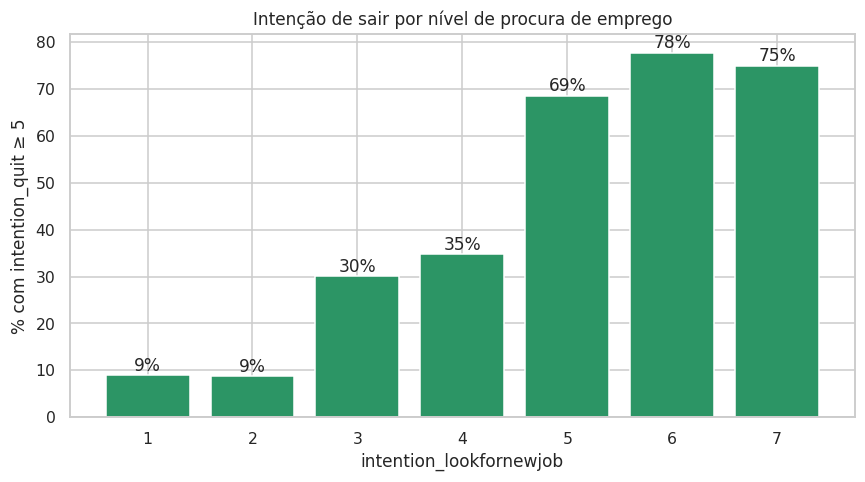

In [ ]:
# Distribuição dos dois targets e da exaustão — confirmação das médias
target = "intention_lookfornewjob"
quit_col = "intention_quit"

medias_target = df_clean[[target, quit_col, "Exhaustion"]].agg(
    ["count", "mean", "median", "min", "max"]
).T
display(medias_target.round(3))

dist = df_clean[target].value_counts().sort_index()
pct = dist / len(df_clean) * 100
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(dist.index.astype(str), pct.values, color="#287db5")
for bar, valor in zip(bars, pct.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+0.5,
            f"{valor:.1f}%", ha="center")
ax.set_xlabel("Intenção de procurar novo emprego (1–7)")
ax.set_ylabel("% de colaboradores")
ax.set_title("Distribuição de intention_lookfornewjob")
plt.tight_layout()
plt.show()

share = df_clean.groupby(target)[quit_col].apply(lambda s: (s >= 5).mean() * 100)
display(share.to_frame("pct_intention_quit_ge_5").round(1))
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(share.index.astype(str), share.values, color="#2c9565")
for bar, valor in zip(bars, share.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()+1,
            f"{valor:.0f}%", ha="center")
ax.set_xlabel("intention_lookfornewjob")
ax.set_ylabel("% com intention_quit ≥ 5")
ax.set_title("Intenção de sair por nível de procura de emprego")
plt.tight_layout()
plt.show()


## **3.1 Transformação da Variável Target numa Variável Binária**

Como referido anteriormente, pretende-se conceber um modelo do tipo classificador para identificar que colaboradores apresentam maior risco de sair, através da variável `intention_lookfornewjob`. Assim, é necessário transformar esta variável, medida numa escala ordinal (1-7), numa variável binária (0 = resposta inferior a 4; 1 = resposta igual ou superior a 4, definida como sinal precoce de atenção e não como saída futura comprovada).

Para estabelecer o limiar de decisão é necessário recordar o objetivo da escolha desta variável como *target*: identificar colaboradores que apresentam uma propensão forte a querer sair, mas num ponto do *pipeline* em que as medidas a tomar (melhoria das *features* das aplicações empresariais) ainda poderão produzir efeito nesta decisão.

### Distribuição e escolha do limiar

O gráfico anterior mostra que predominam respostas baixas. Vamos comparar, numa tabela calculada a seguir, quantos colaboradores seriam sinalizados com limiares 3, 4 e 5.

### **Cruzamento com `intention_quit`**

Para fundamentar o limiar, cruzou-se `intention_lookfornewjob` com `intention_quit`, que mede um passo seguinte no *pipeline* (a intenção de sair). A percentagem de colaboradores com intenção clara de sair (`intention_quit` ≥ 5) aumenta com o nível de procura de emprego: ronda os 9% nos níveis 1 e 2, 30-35% nos níveis 3 e 4, e passa para cerca de 70% ou mais a partir do nível 5.

Com o limiar ≥ 4, 59% dos colaboradores identificados têm `intention_quit` ≥ 5 e apenas 19% têm `intention_quit` < 4. Com o limiar ≥ 5, a primeira percentagem sobe para 72%, mas apenas 47,5% de todos os colaboradores com intenção clara de sair são identificados (contra 59% com o limiar ≥ 4). Note-se ainda que a variável `intention_quit` apresenta um pico no valor 4 (150 respostas, contra 46 no valor 3 e 72 no valor 5), que pode refletir uma tendência para a resposta neutra no ponto médio da escala, pelo que este valor não é usado como critério de referência.

### **Decisão**

Optou-se pelo limiar **`intention_lookfornewjob` ≥ 4**. Esta escolha justifica-se por:

- **Antecedência:** limiares mais elevados correspondem a colaboradores mais avançados no *pipeline* e com menor margem para intervenção.
- **Custo assimétrico dos erros:** as intervenções previstas (*nudges* nas aplicações internas) são de baixo custo, pelo que um falso negativo pode deixar uma necessidade de apoio por detetar, mas falsos positivos também podem estigmatizar pessoas e exigem cuidado.
- **Equilíbrio de classes:** 24,7% de colaboradores em risco é mais adequado para treinar e avaliar o modelo do que 16,5%.

O nível 4 corresponde a uma zona intermédia (apenas 35% dos colaboradores neste nível têm `intention_quit` ≥ 5), que se assume deliberadamente como sinal precoce e não como decisão tomada.

### **Limitações e análise de sensibilidade**

O limiar é uma escolha em parte arbitrária e implica perder a granularidade da escala ordinal original: colaboradores com respostas muito próximas, mas em lados opostos do limiar, passam a ser tratados como completamente diferentes. Além disso, trata-se de intenções autorreportadas, medidas no mesmo momento, e não de saídas reais. A calibração com `intention_quit` serve como apoio, mas torna a definição de "em risco" parcialmente dependente dessa variável.

Por estes motivos, a coluna original (1-7) é mantida intacta e o limiar é tratado como um parâmetro: comparamos a proporção de respostas sinalizadas pelos limiares 3, 4 e 5 antes de fixar o valor 4. A avaliação preditiva utilizará esse limiar declarado.

In [ ]:
# Tabela de prevalência sob três limiares (objetivo 8: base para sensibilidade)
limiares = [3, 4, 5]
resumo_limiares = pd.DataFrame([{
    "Limiar de resposta": f"≥ {limiar}",
    "N.º classe positiva": int(df_clean[target].ge(limiar).sum()),
    "% classe positiva": 100 * df_clean[target].ge(limiar).mean(),
} for limiar in limiares])
display(resumo_limiares.round(2))

LIMIAR = 4
df_clean["em_risco"] = df_clean[target].ge(LIMIAR).astype(int)
print("Distribuição da classificação operacional:")
display(pd.DataFrame({
    "n": df_clean["em_risco"].value_counts().sort_index(),
    "percentagem": 100 * df_clean["em_risco"].value_counts(normalize=True).sort_index()
}).rename_axis("em_risco").round(2))


Distribuição da classificação operacional:


,Limiar de resposta,N.º classe positiva,% classe positiva
0,≥ 3,231,41.32
1,≥ 4,138,24.69
2,≥ 5,92,16.46


,n,percentagem
em_risco,,
0,421,75.31
1,138,24.69


## **3.2 Correlações, comparações por grupos e testes de hipóteses**

Usamos Spearman porque a maioria dos indicadores vem de escalas ordinais e de distribuições com assimetria. A correlação mede a direção e força da associação monotónica; um valor de p pequeno não demonstra causalidade, e muitas comparações aumentam o risco de resultados ocasionais.


,Correlação de Spearman
age,-0.291
ca_Personal_Development,-0.283
n_children,-0.231
has_children,-0.227
years_in_company,-0.181
Feedback,-0.171
ca_leadersCredibility,-0.167
ca_leaderCommunication,-0.163
ca_work_family,-0.155
ca_justice,-0.145


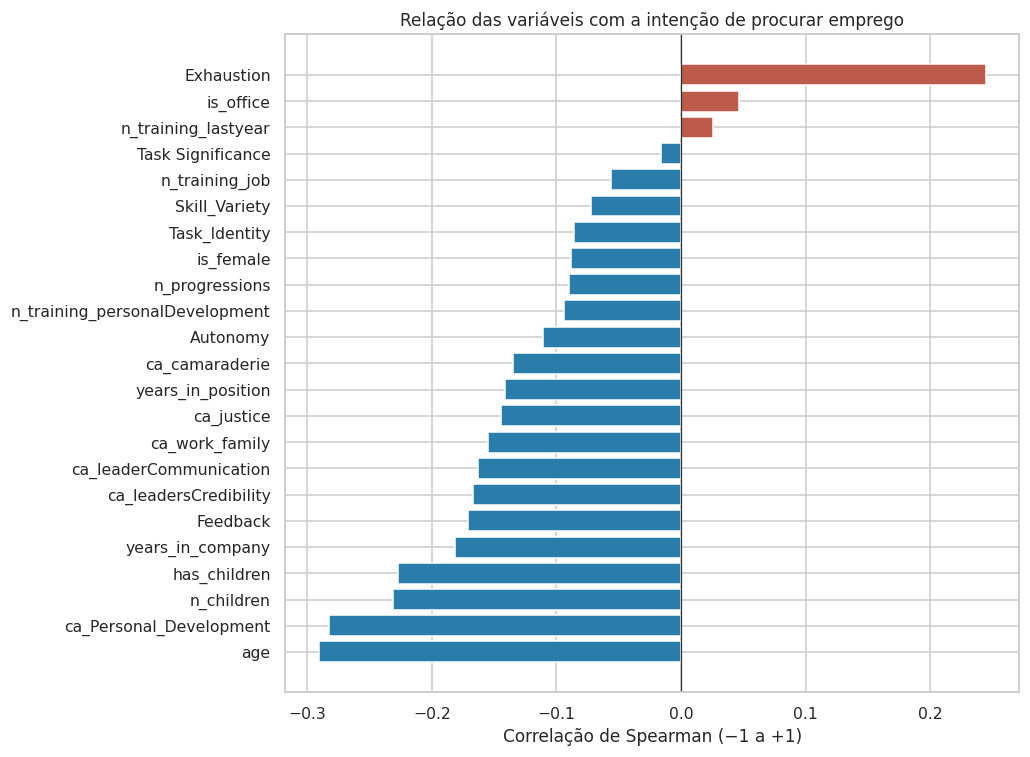

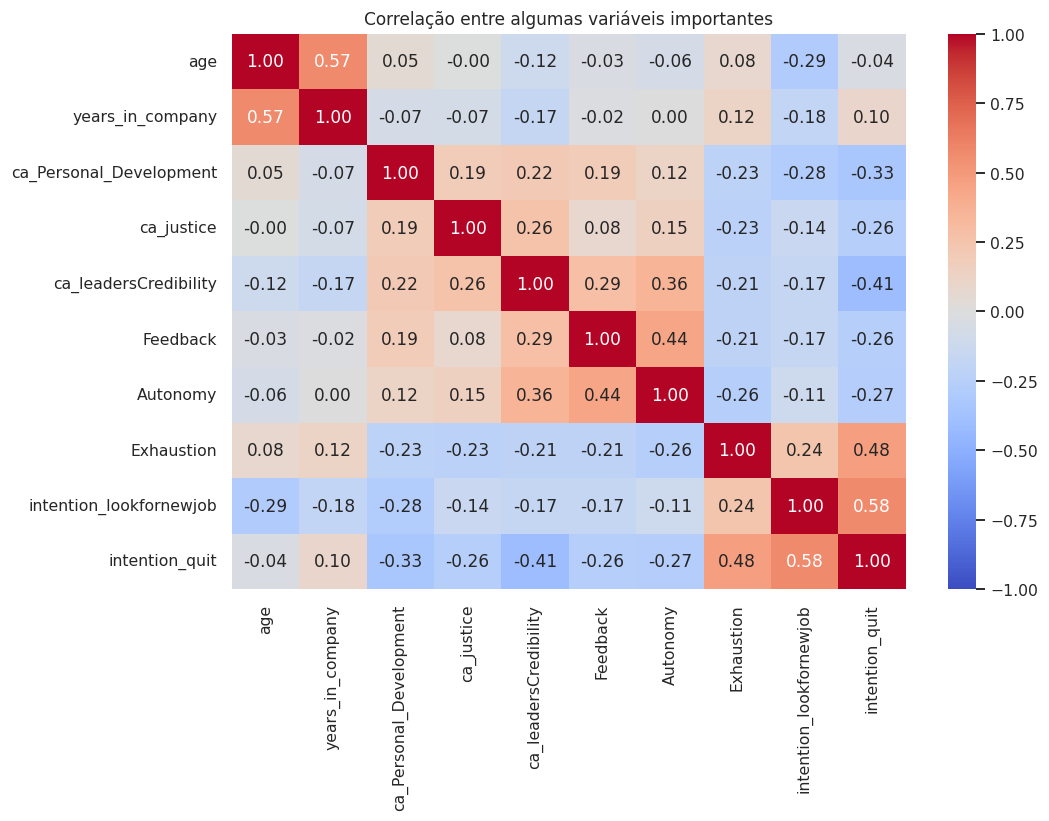

In [ ]:
# Spearman é adequado para estudar tendências nas respostas de escalas ordinais.
# Excluímos identificadores e categorias sem ordem numérica.
excluir_correlacao = [
    "indice", "marital status", "position_in_Company", "em_risco"
]
variaveis_numericas = [c for c in df_clean if c not in excluir_correlacao]
matriz_correlacoes = df_clean[variaveis_numericas].corr(method="spearman")

# A tabela mostra todas as associações com a pergunta que queremos estudar.
correlacao_target = matriz_correlacoes[target].drop(
    [target, quit_col], errors="ignore"
).sort_values()
display(correlacao_target.to_frame("Correlação de Spearman").round(3))

fig, eixo = plt.subplots(figsize=(9.5, 7.0))
cores = ["#bc5b4c" if rho > 0 else "#2a7daa" for rho in correlacao_target]
eixo.barh(correlacao_target.index, correlacao_target.values, color=cores)
eixo.axvline(0, color="#303030", lw=0.8)
eixo.set(title="Relação das variáveis com a intenção de procurar emprego",
         xlabel="Correlação de Spearman (−1 a +1)", ylabel="")
plt.tight_layout()
plt.show()

# O mapa de calor facilita a leitura de algumas relações entre as variáveis.
principais = [
    "age", "years_in_company", "ca_Personal_Development",
    "ca_justice", "ca_leadersCredibility", "Feedback",
    "Autonomy", "Exhaustion", target, quit_col,
]
fig, eixo = plt.subplots(figsize=(10, 7.6))
sns.heatmap(matriz_correlacoes.loc[principais, principais],
            annot=True, fmt=".2f", center=0, vmin=-1, vmax=1,
            cmap="coolwarm", ax=eixo)
eixo.set_title("Correlação entre algumas variáveis importantes")
plt.tight_layout()
plt.show()

### Comparação entre grupos

A correlação mostra a direção geral de uma relação, mas não apresenta diretamente a percentagem de pessoas com intenção elevada em cada faixa. Por isso, vamos comparar grupos de idade, antiguidade, exaustão, desenvolvimento e outras características. Mantemos a linha horizontal da média da amostra para facilitar a leitura dos gráficos.

Faixas de idade:
Antiguidade na empresa:
Género (0 = masculino; 1 = feminino):


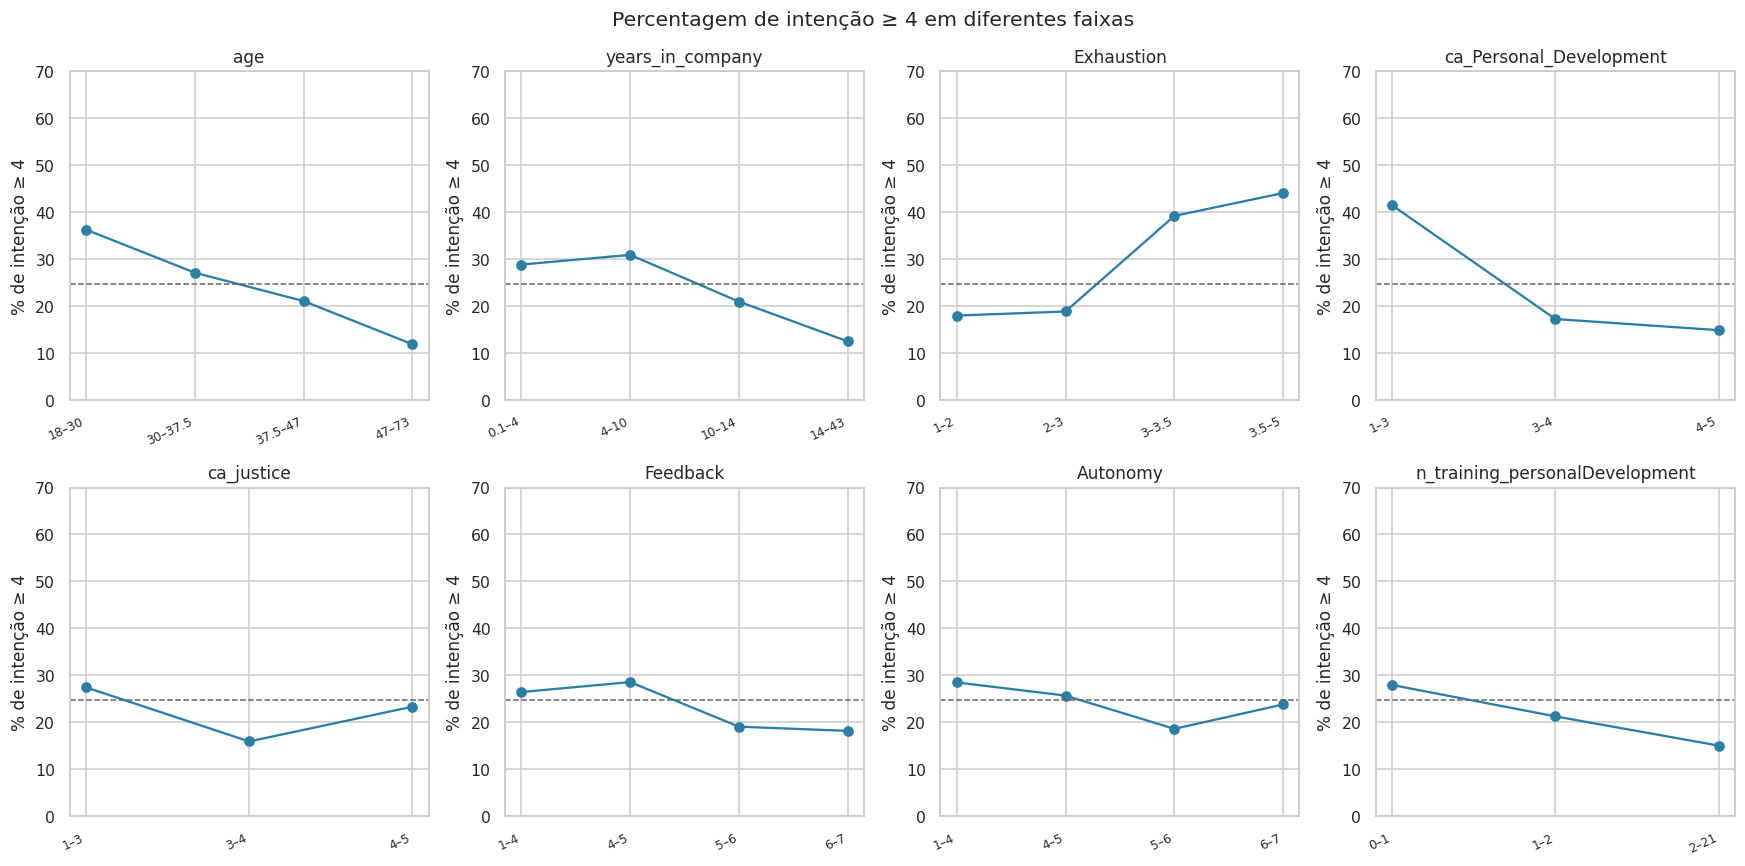

,Colaboradores,% de intenção ≥ 4
faixa_idade,,
16–25,52,46.2
26–35,193,28.0
36–45,151,24.5
46–55,129,16.3
56+,34,5.9


,Colaboradores,% de intenção ≥ 4
faixa_antiguidade,,
0–2,101,29.7
3–5,76,30.3
6–10,124,29.8
11–20,210,21.4
21+,48,6.2


,Colaboradores,% de intenção ≥ 4
is_female,,
0,311,26.7
1,248,22.2


In [ ]:
variaveis_grupos = [
    "age", "years_in_company", "Exhaustion", "ca_Personal_Development",
    "ca_justice", "Feedback", "Autonomy",
    "n_training_personalDevelopment",
]
taxa_global = 100 * df_clean["em_risco"].mean()
fig, eixos = plt.subplots(2, 4, figsize=(16, 8))
for eixo, coluna in zip(eixos.flatten(), variaveis_grupos):
    faixas = pd.qcut(df_clean[coluna], q=4, duplicates="drop")
    tabela_grupos = df_clean.groupby(faixas, observed=True)["em_risco"].agg(
        ["count", "mean"]
    )
    posicoes = np.arange(len(tabela_grupos))
    valores = 100 * tabela_grupos["mean"]
    eixo.plot(posicoes, valores, "o-", color="#2c7ea5")
    eixo.axhline(taxa_global, color="#666666", linestyle="--", lw=1)
    eixo.set_xticks(posicoes)
    eixo.set_xticklabels(
        [f"{max(0, round(faixa.left + 0.001, 1)):g}–{faixa.right:g}"
         for faixa in tabela_grupos.index],
        rotation=25, ha="right", fontsize=8,
    )
    eixo.set(title=coluna, ylim=(0, 70), ylabel="% de intenção ≥ 4")
fig.suptitle("Percentagem de intenção ≥ 4 em diferentes faixas")
plt.tight_layout()
plt.show()

# Faixas simples, com número de pessoas, para apoiar a discussão de H5 e H7.
df_clean["faixa_idade"] = pd.cut(
    df_clean["age"], [15, 25, 35, 45, 55, 100],
    labels=["16–25", "26–35", "36–45", "46–55", "56+"],
)
df_clean["faixa_antiguidade"] = pd.cut(
    df_clean["years_in_company"], [-0.1, 2, 5, 10, 20, 100],
    labels=["0–2", "3–5", "6–10", "11–20", "21+"],
)

def tabela_de_grupos(coluna):
    resultado = df_clean.groupby(coluna, observed=True)["em_risco"].agg(
        Colaboradores="size",
        **{"% de intenção ≥ 4": lambda s: s.mean() * 100},
    )
    return resultado.round(1)

print("Faixas de idade:")
display(tabela_de_grupos("faixa_idade"))
print("Antiguidade na empresa:")
display(tabela_de_grupos("faixa_antiguidade"))
print("Género (0 = masculino; 1 = feminino):")
display(tabela_de_grupos("is_female"))

## 3.3 Resultados das hipóteses

As hipóteses foram definidas no ponto 1, antes de estudar as relações. Nesta fase comparamos o sinal e a intensidade das correlações de Spearman com as direções esperadas. As percentagens por grupos ajudam a perceber algumas dessas relações.

| Hipótese | Evidência observada | Conclusão |
|---|---|---|
| **H1 — Clima organizacional** | Os seis itens de clima apresentam correlações negativas com a intenção de procurar emprego, aproximadamente entre −0,14 e −0,28. | **Apoiada**, embora as associações sejam sobretudo modestas. |
| **H2 — Características das tarefas** | A maioria das correlações é negativa, mas fraca; o feedback destaca-se (aproximadamente −0,17). | **Apoio limitado**; não é um fator tão evidente como se esperava. |
| **H3 — Exaustão** | A correlação com a intenção é positiva (aproximadamente +0,25). | **Apoiada**. |
| **H4 — Desenvolvimento** | Desenvolvimento pessoal tem correlação negativa mais clara (−0,28); número de progressões apresenta relação mais fraca (aproximadamente −0,09). | **Parcialmente apoiada**. |
| **H5 — Antiguidade** | Anos na empresa e na função mostram associações negativas (aproximadamente −0,18 e −0,14). As faixas não revelam uma curva em U nítida. | Existe uma **tendência negativa**, mas a relação não linear prevista não foi demonstrada. |
| **H6 — Formação** | Os indicadores de formação e progressões estão próximos de correlação nula. | **Não apoiada de forma convincente**. |
| **H7 — Idade e género** | A idade tem relação negativa (aproximadamente −0,29); o género apresenta uma diferença mais pequena (aproximadamente −0,09). | **Exploratória**: a idade merece atenção, sem afirmar causas. |

### O que nos surpreendeu?

Esperávamos uma relação mais clara com a formação e as progressões, mas os dados não a mostram. Por outro lado, a idade, a exaustão e a perceção de desenvolvimento pessoal apresentam relações mais visíveis. Isto é útil para formular perguntas de gestão, mas **não prova que uma variável provoque alterações noutra**.

O estudo reúne três empresas sem indicar a origem de cada resposta. As relações identificadas representam a amostra conjunta, não resultados comprovados para cada empresa. Além disso, o preenchimento de respostas em falta pode atenuar ou alterar algumas associações.

## 3.4 Engenharia de variáveis: dois resumos fáceis de interpretar

Os slides de *feature engineering* mostram que podemos criar variáveis derivadas quando estas resumem informação útil. Para descrever o ambiente profissional, calculamos a **média dos seis itens de clima** (todos na escala de 1 a 5) e a **média das cinco características das tarefas** (todas na escala de 1 a 7).

Estes resumos são usados **apenas na descrição**, não substituem os itens individuais no modelo supervisionado. Assim, os efeitos de cada pergunta continuam identificáveis. Também não somamos as três contagens de formação, porque não podemos garantir que representem cursos diferentes.

,Colaboradores,Clima_medio,Tarefas_medio,Exaustao_media
Intenção < 4,421,3.39,4.78,2.8
Intenção ≥ 4,138,3.18,4.71,3.2


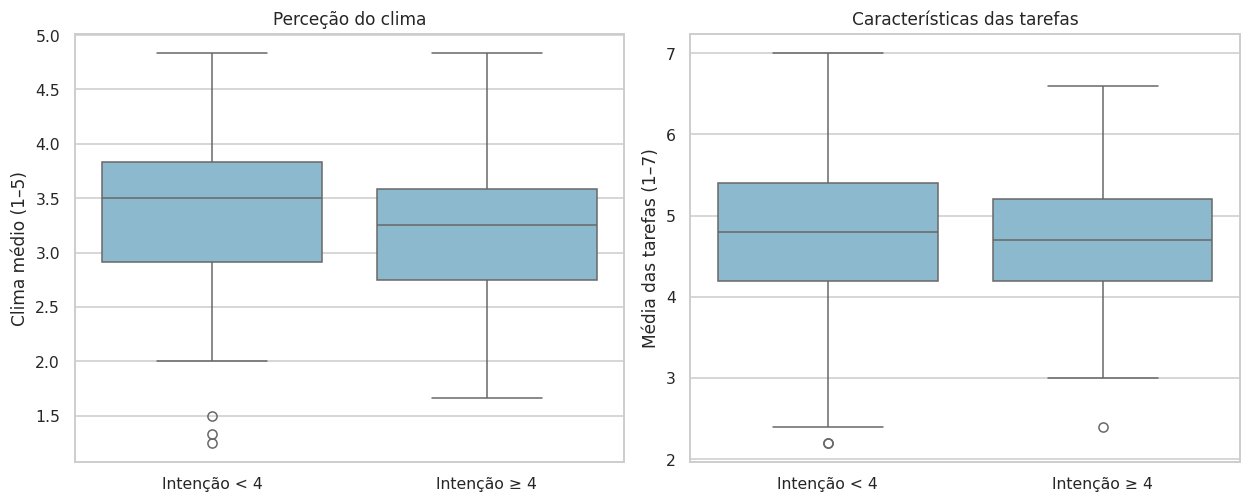

In [ ]:
itens_clima_p3 = [
    "ca_camaraderie", "ca_leadersCredibility", "ca_leaderCommunication",
    "ca_Personal_Development", "ca_justice", "ca_work_family",
]
itens_tarefas_p3 = [
    "Skill_Variety", "Task_Identity", "Task Significance",
    "Autonomy", "Feedback",
]
df_clean["clima_medio"] = df_clean[itens_clima_p3].mean(axis=1)
df_clean["tarefas_medio"] = df_clean[itens_tarefas_p3].mean(axis=1)

tabela_medias_grupos = df_clean.groupby("em_risco").agg(
    Colaboradores=("age", "size"),
    Clima_medio=("clima_medio", "mean"),
    Tarefas_medio=("tarefas_medio", "mean"),
    Exaustao_media=("Exhaustion", "mean"),
)
tabela_medias_grupos.index = ["Intenção < 4", "Intenção ≥ 4"]
display(tabela_medias_grupos.round(2))

fig, eixos = plt.subplots(1, 2, figsize=(11.5, 4.7))
sns.boxplot(data=df_clean, x="em_risco", y="clima_medio",
            color="#81bdd9", ax=eixos[0])
sns.boxplot(data=df_clean, x="em_risco", y="tarefas_medio",
            color="#81bdd9", ax=eixos[1])
for eixo, titulo, etiqueta in [
    (eixos[0], "Perceção do clima", "Clima médio (1–5)"),
    (eixos[1], "Características das tarefas", "Média das tarefas (1–7)"),
]:
    eixo.set_xticks([0, 1], ["Intenção < 4", "Intenção ≥ 4"])
    eixo.set(xlabel="", ylabel=etiqueta, title=titulo)
plt.tight_layout()
plt.show()

**Ligação ao ponto 4:** até aqui descrevemos diferenças nos dados existentes. Falta responder a outra pergunta: será que conseguimos identificar uma classe de intenção elevada em respostas que o modelo ainda não viu? Para isso, precisamos de reservar dados para teste e usar um algoritmo de classificação.

In [ ]:
df_eda = df_clean.copy()
df_eda["em_alerta"] = df_eda["em_risco"].astype(int)
ALVO = target
ALERTA = LIMIAR
print("Prosseguimos com 559 colaboradores; treino e teste serão separados no ponto 4.")

Prosseguimos com 559 colaboradores; treino e teste serão separados no ponto 4.


# 4. Modelo supervisionado — Podemos prever o sinal de intenção?

## 4.1 Porque escolhemos regressão logística e não regressão linear?

A **regressão linear** é utilizada principalmente quando queremos prever um **número contínuo**, como um valor de consumo ou uma temperatura. Se a aplicássemos diretamente a uma classe 0/1, poderia produzir valores inferiores a 0 ou superiores a 1 e não seria o método mais adequado para a nossa tarefa.

A **regressão logística**, apesar do nome semelhante, é um **algoritmo de classificação**. É apropriada quando a resposta tem duas categorias: neste caso, intenção **inferior a 4** ou **igual/superior a 4**. Produz uma pontuação entre 0 e 1, que podemos utilizar para classificar a resposta. **Não é a probabilidade comprovada de alguém se demitir**, porque a nossa variável mede apenas a intenção declarada.

| Alternativa | Vantagem | Porque não é a primeira escolha aqui? |
|---|---|---|
| **Regressão linear** | Simples para prever valores numéricos. | A nossa resposta operacional tem duas classes, não é um valor contínuo. |
| **Regressão logística** | Adequada a duas classes e relativamente fácil de interpretar. | É a **escolha principal**, que vamos avaliar. |
| **Árvore de decisão / Random Forest** | Podem captar relações mais complexas. | São úteis para comparação, mas a interpretação global pode ser mais difícil. |
| **KNN** | Classifica por semelhança com respostas próximas. | Com muitas variáveis, a ideia de «proximidade» pode tornar-se menos intuitiva. |

Vamos comparar um modelo muito simples (que escolhe sempre a classe mais frequente), duas versões de regressão logística e uma floresta aleatória. Esta comparação serve para justificar a escolha com dados, não apenas por preferência.

## 4.2 Como avaliamos uma previsão de forma honesta?

Reservamos **30% dos colaboradores para teste** e utilizamos os restantes **70% para treino**. A divisão é estratificada: procura manter aproximadamente a mesma percentagem de respostas ≥ 4 nos dois conjuntos. O conjunto de teste só é usado no final.

In [ ]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate

# Excluímos o identificador, as respostas que queremos explicar e as categorias
# sem tratamento nominal. n_children é mantida nos dados, mas não entra no modelo.
excluir_modelo = {
    "indice", "marital status", "position_in_Company", "n_children",
    "intention_lookfornewjob", "intention_quit",
}
variaveis_modelo = [col for col in df_sem_imputacao if col not in excluir_modelo]
X = df_sem_imputacao[variaveis_modelo].copy()
y = df_sem_imputacao[ALVO].ge(ALERTA).astype(int)

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)
display(pd.DataFrame({
    "Conjunto": ["Treino", "Teste", "Total"],
    "Colaboradores": [len(y_treino), len(y_teste), len(y)],
    "Com intenção ≥ 4": [int(y_treino.sum()), int(y_teste.sum()), int(y.sum())],
    "% com intenção ≥ 4": [
        100 * y_treino.mean(), 100 * y_teste.mean(), 100 * y.mean()
    ],
}).round(1))
print("Características usadas no modelo:", len(variaveis_modelo))
assert len(variaveis_modelo) == 22
assert (len(y_treino), len(y_teste)) == (391, 168)
assert not {"indice", ALVO, "intention_quit"} & set(variaveis_modelo)

Características usadas no modelo: 22


,Conjunto,Colaboradores,Com intenção ≥ 4,% com intenção ≥ 4
0,Treino,391,97,24.8
1,Teste,168,41,24.4
2,Total,559,138,24.7


## 4.3 Como preparamos as respostas durante o treino?

Algumas variáveis ainda têm valores em falta. Para não dar ao modelo informações que só existem no conjunto de teste, o preenchimento pela mediana é feito **dentro de uma sequência automatizada de preparação** (*Pipeline*) que aprende apenas com os dados de treino.

Também mantemos a regra de que os anos na função não podem ultrapassar os anos na empresa. Depois, colocamos as variáveis na mesma escala para que uma diferença de unidades não distorça a regressão logística.

Existem menos respostas na classe de intenção ≥ 4. Por isso, avaliamos também uma regressão logística que dá **maior peso a essa classe durante o treino**. O objetivo é não ignorar as respostas de maior intenção, embora isso possa aumentar os falsos alarmes.

In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier


class RespeitarAntiguidade(BaseEstimator, TransformerMixin):
    # Preenche antiguidade sem criar anos na função > anos na empresa.
    def fit(self, dados, y=None):
        self.med_empresa_ = dados["years_in_company"].median()
        self.med_funcao_ = dados["years_in_position"].median()
        return self

    def transform(self, dados):
        dados = dados.copy()
        dados["years_in_company"] = dados["years_in_company"].fillna(
            np.maximum(self.med_empresa_, dados["years_in_position"].fillna(0))
        )
        dados["years_in_position"] = dados["years_in_position"].fillna(
            np.minimum(self.med_funcao_, dados["years_in_company"])
        )
        dados["years_in_position"] = np.minimum(
            dados["years_in_position"], dados["years_in_company"]
        )
        return dados


def criar_logistica(ponderar=False):
    return Pipeline([
        ("antiguidade", RespeitarAntiguidade()),
        ("preencher", SimpleImputer(strategy="median")),
        ("normalizar", StandardScaler()),
        ("modelo", LogisticRegression(
            class_weight="balanced" if ponderar else None,
            max_iter=2000, random_state=42
        )),
    ])


modelos_supervisionados = {
    "Referência: classe mais frequente": DummyClassifier(strategy="most_frequent"),
    "Regressão logística": criar_logistica(ponderar=False),
    "Regressão logística ponderada": criar_logistica(ponderar=True),
    "Random Forest": Pipeline([
        ("antiguidade", RespeitarAntiguidade()),
        ("preencher", SimpleImputer(strategy="median")),
        ("modelo", RandomForestClassifier(
            n_estimators=300, max_depth=5, min_samples_leaf=5,
            class_weight="balanced", random_state=42,
        )),
    ]),
}
print("Modelos que vamos comparar:", ", ".join(modelos_supervisionados))

Modelos que vamos comparar: Referência: classe mais frequente, Regressão logística, Regressão logística ponderada, Random Forest


## 4.4 Como escolhemos o melhor modelo?

Usamos **validação cruzada com 5 divisões** *apenas dentro do treino*. Assim, a escolha não depende de uma única divisão dos dados.

As métricas respondem a perguntas diferentes:

- **Recall:** de todas as respostas ≥ 4, quantas o modelo conseguiu identificar? É a nossa prioridade.
- **Precision:** de todas as respostas sinalizadas pelo modelo, quantas eram realmente ≥ 4?
- **F1:** procura equilibrar Recall e Precision.
- **ROC-AUC:** mede a capacidade global de distinguir as duas classes.

Um modelo que identifica toda a gente como «intenção baixa» pode acertar muitas respostas, mas não é útil para identificar a classe menos frequente. Por isso, não escolhemos apenas pela percentagem total de acertos.

In [ ]:
from sklearn.metrics import make_scorer, precision_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metricas_cv = {
    "Recall": "recall",
    "Precision": make_scorer(precision_score, zero_division=0),
    "F1": "f1",
    "ROC-AUC": "roc_auc",
}

linhas_cv = []
for nome, modelo in modelos_supervisionados.items():
    resultado = cross_validate(
        modelo, X_treino, y_treino, cv=cv,
        scoring=metricas_cv, error_score="raise"
    )
    linha = {"Modelo": nome}
    for nome_metrica in metricas_cv:
        valores = resultado[f"test_{nome_metrica}"]
        linha[nome_metrica] = valores.mean()
        linha[f"{nome_metrica} — desvio"] = valores.std()
    linhas_cv.append(linha)

avaliacao_cv = pd.DataFrame(linhas_cv)
display(avaliacao_cv[["Modelo", "Recall", "Precision", "F1", "ROC-AUC"]].round(3))

print("A tabela apresenta a média das 5 divisões. A variabilidade foi",
      "calculada e pode ser consultada no objeto avaliacao_cv.")

A tabela apresenta a média das 5 divisões. A variabilidade foi calculada e pode ser consultada no objeto avaliacao_cv.


,Modelo,Recall,Precision,F1,ROC-AUC
0,Referência: classe mais frequente,0.000,0.000,0.000,0.500
1,Regressão logística,0.351,0.585,0.423,0.743
2,Regressão logística ponderada,0.639,0.451,0.523,0.747
3,Random Forest,0.496,0.537,0.506,0.751


**Escolha fundamentada:** a **regressão logística ponderada** apresentou, na validação, a maior capacidade média de identificar a classe ≥ 4 (*Recall* perto de 64%), com uma precisão que continua a exigir prudência. A regressão logística sem ponderação assinalou menos casos; a Random Forest também foi comparada, mas não apresentou melhor *Recall*.

Selecionamos a regressão logística ponderada porque é adequada à classificação binária, oferece uma explicação mais direta e responde melhor à prioridade definida com os RH. **Ainda não utilizámos o conjunto de teste para tomar esta decisão.**

## 4.5 O que acontece quando aplicamos o modelo ao teste?

,Métrica,Resultado no teste
0,Accuracy,0.655
1,Balanced accuracy,0.648
2,Recall,0.634
3,Precision,0.377
4,F1,0.473
5,ROC-AUC,0.705


,Resultado,Colaboradores
0,Identificados corretamente (TP),26
1,Não identificados (FN),15
2,Falsos alarmes (FP),43
3,Negativos corretamente identificados (TN),84


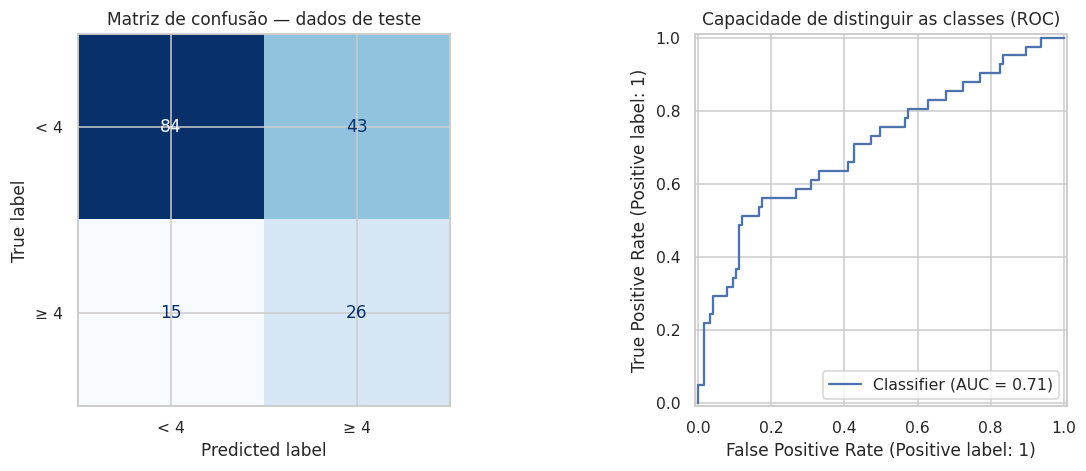

In [ ]:
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
)

modelo_escolhido = modelos_supervisionados["Regressão logística ponderada"]
modelo_escolhido.fit(X_treino, y_treino)
previsoes = modelo_escolhido.predict(X_teste)
pontuacoes = modelo_escolhido.predict_proba(X_teste)[:, 1]

tn, fp, fn, tp = confusion_matrix(y_teste, previsoes).ravel()
metricas_teste = pd.DataFrame({
    "Métrica": ["Accuracy", "Balanced accuracy", "Recall", "Precision",
                "F1", "ROC-AUC"],
    "Resultado no teste": [
        accuracy_score(y_teste, previsoes),
        balanced_accuracy_score(y_teste, previsoes),
        recall_score(y_teste, previsoes),
        precision_score(y_teste, previsoes, zero_division=0),
        f1_score(y_teste, previsoes),
        roc_auc_score(y_teste, pontuacoes),
    ],
})
display(metricas_teste.round(3))
display(pd.DataFrame({
    "Resultado": ["Identificados corretamente (TP)",
                  "Não identificados (FN)",
                  "Falsos alarmes (FP)",
                  "Negativos corretamente identificados (TN)"],
    "Colaboradores": [tp, fn, fp, tn],
}))

fig, eixos = plt.subplots(1, 2, figsize=(11.8, 4.4))
ConfusionMatrixDisplay.from_predictions(
    y_teste, previsoes, display_labels=["< 4", "≥ 4"],
    cmap="Blues", colorbar=False, ax=eixos[0]
)
eixos[0].set_title("Matriz de confusão — dados de teste")
RocCurveDisplay.from_predictions(y_teste, pontuacoes, ax=eixos[1])
eixos[1].set_title("Capacidade de distinguir as classes (ROC)")
plt.tight_layout()
plt.show()

assert (tn, fp, fn, tp) == (84, 43, 15, 26)

## 4.6 O que significam estes resultados?

Dos **41 colaboradores do conjunto de teste** que declararam intenção ≥ 4, o modelo identificou corretamente **26** e não identificou **15**. Isto corresponde a um **Recall de 63,4%**.

Ao mesmo tempo, o modelo assinalou **69 colaboradores**, mas apenas **26** tinham realmente respondido ≥ 4. Isto significa que a **Precision foi de 37,7%**: existem falsos alarmes importantes.

A percentagem global de acertos foi de aproximadamente **65,5%**. Se prevíssemos sempre a classe mais frequente, conseguiríamos cerca de **75,6%** de acertos, mas não identificaríamos **nenhum** colaborador da classe ≥ 4. É por isso que o Recall é tão importante para esta pergunta.

**O que aprendemos?** O modelo identifica parte das respostas de intenção mais elevada, mas está longe de ser infalível. Não deve ser utilizado para decisões automáticas sobre pessoas. Além disso, os dados são de um único momento e não permitem medir saídas futuras ou validar resultados em cada empresa.

Para compreender *que características* acompanham estas previsões, podemos consultar os coeficientes da regressão logística. Valores positivos contribuem para aumentar a pontuação da classe ≥ 4 e negativos para a reduzir, sempre **condicionados às restantes variáveis do modelo**. Não provam relações de causa e efeito.

,Variável,Coeficiente
18,ca_Personal_Development,-0.827
0,age,-0.484
8,n_training_personalDevelopment,-0.459
5,years_in_company,-0.290
2,is_female,-0.275
19,ca_justice,-0.269
7,n_training_job,-0.231
14,Feedback,-0.228
20,ca_work_family,0.243
10,Skill_Variety,0.336


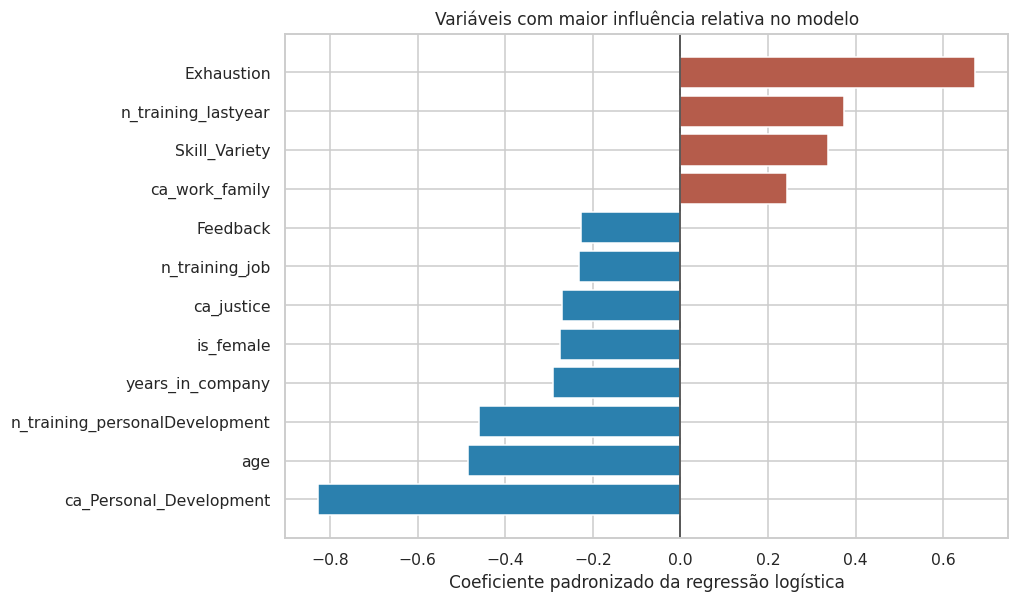

In [ ]:
coeficientes = pd.DataFrame({
    "Variável": variaveis_modelo,
    "Coeficiente": modelo_escolhido.named_steps["modelo"].coef_[0],
})
top_coeficientes = (
    coeficientes.assign(intensidade=lambda d: d["Coeficiente"].abs())
    .nlargest(12, "intensidade")
    .sort_values("Coeficiente")
)
display(top_coeficientes[["Variável", "Coeficiente"]].round(3))

fig, ax = plt.subplots(figsize=(9.4, 5.6))
cores = ["#b55c4b" if x > 0 else "#2b80ae" for x in top_coeficientes["Coeficiente"]]
ax.barh(top_coeficientes["Variável"], top_coeficientes["Coeficiente"], color=cores)
ax.axvline(0, color="#333333", linewidth=1)
ax.set(title="Variáveis com maior influência relativa no modelo",
       xlabel="Coeficiente padronizado da regressão logística", ylabel="")
plt.tight_layout()
plt.show()

**Conclusão do ponto 4:** conseguimos construir e avaliar uma previsão, mas os erros mostram que ela é apenas um **apoio exploratório**. A capacidade de identificar sinais de intenção não explica, por si só, se todos os colaboradores vivem situações semelhantes.

Por isso, passamos à próxima pergunta: **será que existem perfis de experiência laboral diferentes, para os quais as empresas devam considerar abordagens distintas?**

# 5. Análise não supervisionada — Existem perfis diferentes?

## 5.1 O que faz o K-Means?

O **K-Means** agrupa pessoas que apresentam respostas semelhantes, sem lhe dizermos antecipadamente quem tem maior intenção de procurar emprego. Ao contrário da regressão logística, **não tenta prever uma classe**. Procura padrões nas características do trabalho.

Utilizamos **12 respostas do questionário**: seis sobre o clima organizacional, cinco sobre as características das tarefas e uma sobre a exaustão. Excluímos da formação dos grupos a intenção de procurar emprego, a intenção de sair, a idade e o género. A intenção de procurar emprego só será comparada **depois** de os grupos estarem formados.

Como as perguntas não têm todas a mesma escala, começamos por **padronizar as variáveis** (colocá-las em unidades comparáveis). Os valores em falta são preenchidos com a mediana. Cada item do questionário recebe o mesmo tratamento; como existem mais perguntas sobre clima, esse bloco pode ter maior influência e isso deve ser lembrado na interpretação.

## 5.2 Quantos grupos devemos escolher?

O enunciado exige justificar o número de clusters. Por isso, testamos várias alternativas:

- **Elbow:** observa quanto melhora a proximidade dentro dos grupos quando aumentamos o número de clusters.
- **Silhouette:** avalia se as pessoas estão mais próximas do seu próprio grupo do que dos outros. Valores maiores são geralmente preferíveis.

Vamos comparar **2 a 8 grupos**, mantendo o número que apresenta a maior Silhouette média e verificando também o gráfico Elbow.

  File "/opt/codex/runtimes/codex-primary-runtime/dependencies/python/lib/python3.12/site-packages/joblib/externals/loky/backend/context.py", line 255, in _count_physical_cores
    raise ValueError(f"found {cpu_count_physical} physical cores < 1")
Número escolhido: 2 grupos.


,N.º de grupos,Inertia,Silhouette,Menor grupo (n)
0,1,6708.000,NaN,559
1,2,5143.942,0.224,211
2,3,4698.389,0.161,95
3,4,4372.643,0.130,74
4,5,4149.962,0.123,70
5,6,3999.066,0.116,70
6,7,3859.836,0.118,44
7,8,3742.471,0.119,42


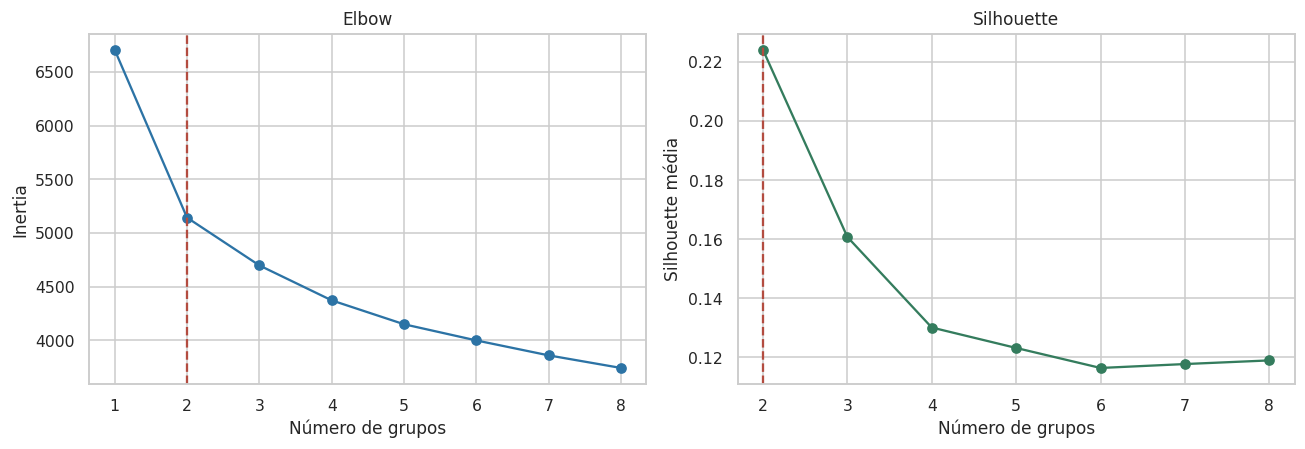

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

itens_clima = [
    "ca_camaraderie", "ca_leadersCredibility", "ca_leaderCommunication",
    "ca_Personal_Development", "ca_justice", "ca_work_family",
]
itens_trabalho = [
    "Skill_Variety", "Task_Identity", "Task Significance", "Autonomy", "Feedback",
]
itens_cluster = itens_clima + itens_trabalho + ["Exhaustion"]

# A variável alvo não participa na formação dos segmentos.
X_clusters_original = df_sem_imputacao[itens_cluster]
imputacao_clusters = SimpleImputer(strategy="median")
escala_clusters = StandardScaler()
X_clusters_preenchido = pd.DataFrame(
    imputacao_clusters.fit_transform(X_clusters_original),
    index=X_clusters_original.index, columns=itens_cluster,
)
Z_clusters = escala_clusters.fit_transform(X_clusters_preenchido)

comparacao_clusters = []
for k in range(1, 9):
    tentativa = KMeans(n_clusters=k, n_init=20, random_state=42)
    grupos = tentativa.fit_predict(Z_clusters)
    comparacao_clusters.append({
        "N.º de grupos": k,
        "Inertia": tentativa.inertia_,
        "Silhouette": np.nan if k == 1 else silhouette_score(Z_clusters, grupos),
        "Menor grupo (n)": int(pd.Series(grupos).value_counts().min()),
    })

tabela_k = pd.DataFrame(comparacao_clusters)
display(tabela_k.round(3))
numero_grupos = int(tabela_k.loc[tabela_k["Silhouette"].idxmax(), "N.º de grupos"])

fig, eixos = plt.subplots(1, 2, figsize=(12, 4.2))
eixos[0].plot(tabela_k["N.º de grupos"], tabela_k["Inertia"], "o-", color="#2c73a5")
eixos[0].axvline(numero_grupos, color="#b34c40", linestyle="--")
eixos[0].set(title="Elbow", xlabel="Número de grupos", ylabel="Inertia")
eixos[1].plot(tabela_k.loc[tabela_k["N.º de grupos"] >= 2, "N.º de grupos"],
              tabela_k.loc[tabela_k["N.º de grupos"] >= 2, "Silhouette"],
              "o-", color="#347c5d")
eixos[1].axvline(numero_grupos, color="#b34c40", linestyle="--")
eixos[1].set(title="Silhouette", xlabel="Número de grupos", ylabel="Silhouette média")
plt.tight_layout()
plt.show()
print(f"Número escolhido: {numero_grupos} grupos.")
assert numero_grupos == 2

**Decisão:** a comparação favoreceu **2 grupos**, com Silhouette média próxima de **0,224**, superior aos resultados para 3 ou mais grupos. Esta pontuação não é elevada, portanto **há sobreposição entre os perfis**. A segmentação deve ajudar a compreender padrões gerais, não criar rótulos permanentes para cada trabalhador.

## 5.3 Como são os grupos encontrados?

Depois de formar os clusters, calculamos as médias do clima, das tarefas e da exaustão em cada grupo. **Só agora** comparamos a percentagem de respostas com intenção de procurar emprego ≥ 4.

In [ ]:
modelo_clusters = KMeans(n_clusters=numero_grupos, n_init=20, random_state=42)
rotulos_kmeans = modelo_clusters.fit_predict(Z_clusters)

# Nomear S1 como o grupo com menor média de clima, só para facilitar a leitura.
clima_por_cluster = (
    X_clusters_preenchido.assign(cluster=rotulos_kmeans)
    .groupby("cluster")[itens_clima].mean().mean(axis=1)
)
mapa_grupos = {
    rotulo: f"S{pos + 1}"
    for pos, rotulo in enumerate(clima_por_cluster.sort_values().index)
}

df_segmentos = df_sem_imputacao[[
    "indice", "age", "is_office", "intention_lookfornewjob", "intention_quit",
]].copy()
df_segmentos["Segmento"] = [mapa_grupos[c] for c in rotulos_kmeans]
df_segmentos["Clima médio (1–5)"] = X_clusters_preenchido[itens_clima].mean(axis=1)
df_segmentos["Trabalho médio (1–7)"] = X_clusters_preenchido[itens_trabalho].mean(axis=1)
df_segmentos["Exaustão (1–5)"] = X_clusters_preenchido["Exhaustion"]
df_segmentos["Intenção ≥ 4"] = df_segmentos[ALVO].ge(ALERTA).astype(int)

perfis = df_segmentos.groupby("Segmento").agg(
    Colaboradores=("indice", "size"),
    Clima=("Clima médio (1–5)", "mean"),
    Trabalho=("Trabalho médio (1–7)", "mean"),
    Exaustao=("Exaustão (1–5)", "mean"),
    Intencao_media=(ALVO, "mean"),
    Respostas_alerta=("Intenção ≥ 4", "sum"),
    Idade_media=("age", "mean"),
)
perfis["% da amostra"] = 100 * perfis["Colaboradores"] / len(df_segmentos)
perfis["% com intenção ≥ 4"] = (
    100 * perfis["Respostas_alerta"] / perfis["Colaboradores"]
)

display(perfis[[
    "Colaboradores", "% da amostra", "Clima", "Trabalho", "Exaustao",
    "Intencao_media", "Respostas_alerta", "% com intenção ≥ 4",
    "Idade_media",
]].round(2))

assert perfis["Colaboradores"].sum() == 559
assert perfis["Respostas_alerta"].sum() == 138

,Colaboradores,% da amostra,Clima,Trabalho,Exaustao,Intencao_media,Respostas_alerta,% com intenção ≥ 4,Idade_media
Segmento,,,,,,,,,
S1,211,37.75,2.70,4.01,3.32,3.09,67,31.75,39.50
S2,348,62.25,3.72,5.21,2.64,2.36,71,20.40,37.76


## 5.4 O que nos mostram os gráficos?

No mapa de calor, vemos se cada grupo ficou acima ou abaixo da média geral em cada pergunta. **Em clima e tarefas, valores maiores são favoráveis; na exaustão, valores maiores são desfavoráveis.**

O gráfico seguinte compara a percentagem de colaboradores com intenção ≥ 4. Essa variável **não foi usada para criar os clusters**; serve apenas para compreender se os perfis encontrados também diferem na intenção declarada.

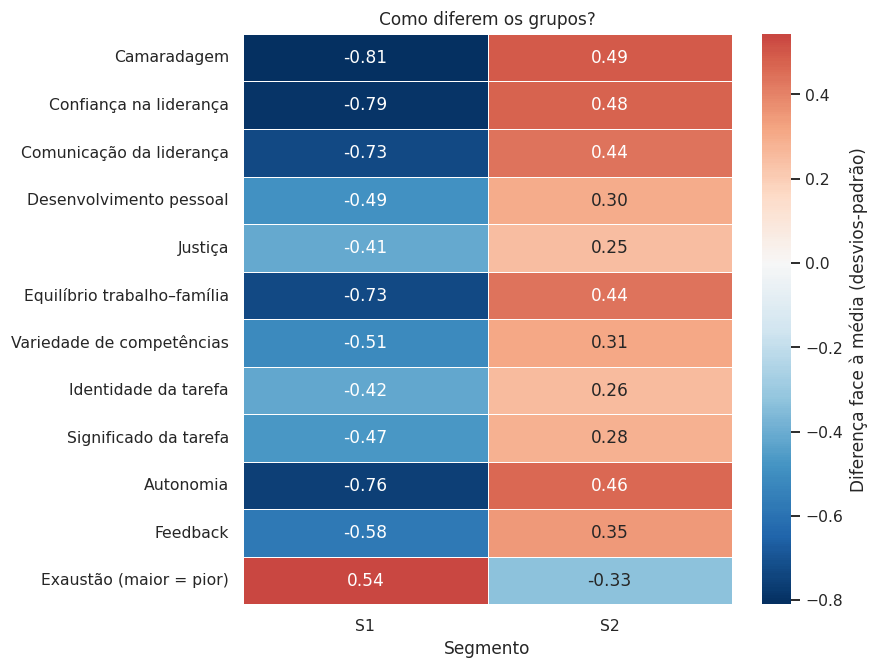

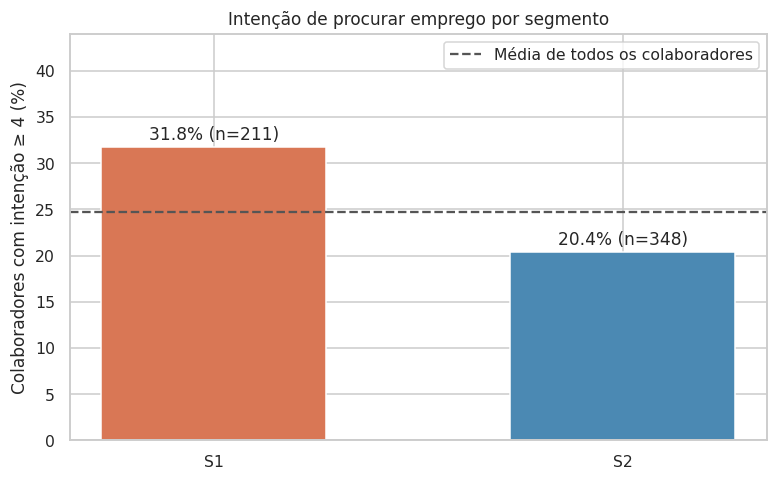

In [ ]:
z_perfis = pd.DataFrame(Z_clusters, index=df_segmentos.index, columns=itens_cluster)
z_perfis["Segmento"] = df_segmentos["Segmento"]
medias_z = z_perfis.groupby("Segmento")[itens_cluster].mean().T
nomes_variaveis = {
    "ca_camaraderie": "Camaradagem",
    "ca_leadersCredibility": "Confiança na liderança",
    "ca_leaderCommunication": "Comunicação da liderança",
    "ca_Personal_Development": "Desenvolvimento pessoal",
    "ca_justice": "Justiça",
    "ca_work_family": "Equilíbrio trabalho–família",
    "Skill_Variety": "Variedade de competências",
    "Task_Identity": "Identidade da tarefa",
    "Task Significance": "Significado da tarefa",
    "Autonomy": "Autonomia",
    "Feedback": "Feedback",
    "Exhaustion": "Exaustão (maior = pior)",
}
medias_z.index = [nomes_variaveis[c] for c in medias_z.index]

fig, ax = plt.subplots(figsize=(8, 6.2))
sns.heatmap(medias_z, annot=True, fmt=".2f", center=0, cmap="RdBu_r",
            linewidths=0.35, cbar_kws={"label": "Diferença face à média (desvios-padrão)"},
            ax=ax)
ax.set(title="Como diferem os grupos?", xlabel="Segmento", ylabel="")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7.2, 4.5))
cores = ["#d97755", "#4b89b3"]
ax.bar(perfis.index, perfis["% com intenção ≥ 4"], color=cores, width=0.55)
ax.axhline(100 * df_segmentos["Intenção ≥ 4"].mean(),
           color="#555555", linestyle="--", label="Média de todos os colaboradores")
for i, (_, linha) in enumerate(perfis.iterrows()):
    ax.text(i, linha["% com intenção ≥ 4"] + 0.8,
            f"{linha['% com intenção ≥ 4']:.1f}% (n={int(linha['Colaboradores'])})",
            ha="center")
ax.set(title="Intenção de procurar emprego por segmento",
       ylabel="Colaboradores com intenção ≥ 4 (%)", ylim=(0, 44))
ax.legend()
plt.tight_layout()
plt.show()

## 5.5 O que concluímos — e o que vem a seguir?

Encontrámos **dois perfis exploratórios**:

- **S1:** 211 colaboradores que, em média, reportam condições de trabalho menos favoráveis. Cerca de **31,8%** apresentaram intenção de procurar emprego ≥ 4.
- **S2:** 348 colaboradores com perceções médias mais favoráveis. Cerca de **20,4%** apresentaram intenção ≥ 4.

Esta diferença de aproximadamente **11,4 pontos percentuais** sugere que as condições vividas pelos colaboradores são relevantes para compreender as respostas. Contudo, os grupos sobrepõem-se e **não podemos afirmar que essas condições causaram a intenção**.

**O que aprendemos ao longo do projeto?** Começámos com dados imperfeitos, limpámo-los, testámos hipóteses, construímos uma previsão e identificámos perfis. A próxima etapa será apresentar estas conclusões num **dashboard interativo**, para os diretores compararem os resultados e ponderarem ações transparentes de apoio.

**Limitações comuns a todo o estudo:** o questionário não mede demissões reais; é uma observação num único momento; faltam identificadores das três empresas; as respostas em falta foram imputadas; os modelos podem falhar e não devem fundamentar decisões automáticas individuais. Os resultados apoiam o diagnóstico e a discussão, mas exigem validação antes de qualquer intervenção real.